# M2 upsample: final comparison

Self-contained 100-trial M2c experiment using exact least-squares WERM.

## Experiment

McScan, charcoal (documented fixed threshold 10; gated through $\delta \leq 9$), and unpenalized WERM with 10-fold CV.

In [ ]:
from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
jax.config.update('jax_enable_x64', True)
import numpy.random as nprandom
import matplotlib.pyplot as plt
# Embed figures in executed notebook output even on a headless compute node.
plt.switch_backend("module://matplotlib_inline.backend_inline")
from functools import partial
from tqdm.auto import tqdm
from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
import time
from joblib import Parallel, delayed
from joblib.externals.loky.process_executor import TerminatedWorkerError
import sys
import pickle
import os
os.environ['JAX_ENABLE_X64']='True'
from pathlib import Path

# Set a random seed for reproducibility
random_seed = 42
CHARCOAL_MAX_DELTA = 9.0
SMOKE_MODE = os.environ.get('WERM_SMOKE') == '1'

def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
    return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
    setting_idx, trial_idx, trial_result = result
    os.makedirs(checkpoint_dir, exist_ok=True)
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    tmp_path = f'{path}.tmp-{os.getpid()}'
    payload = {'signature': checkpoint_signature, 'setting_idx': int(setting_idx), 'trial_idx': int(trial_idx), 'result': result}
    with open(tmp_path, 'wb') as checkpoint_file:
        pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
        checkpoint_file.flush(); os.fsync(checkpoint_file.fileno())
    os.replace(tmp_path, path)

def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
    path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
    if not os.path.exists(path): return None
    try:
        with open(path, 'rb') as checkpoint_file: payload = pickle.load(checkpoint_file)
        if payload.get('signature') != checkpoint_signature: return None
        result = payload['result']
        if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)): return None
        data_hash = result[2].get('data_hash')
        if not isinstance(data_hash, str) or len(data_hash) != 32: return None
        return result
    except Exception as checkpoint_error:
        print(f'Ignoring invalid checkpoint {path}: {checkpoint_error}'); return None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    i, delta, j = params # delta is now the iterating parameter

    rng = _trial_rng("M2c-alpha-0.3", i, j)

    # --- Setup based on delta and fixed noise_scale ---
    n = int(delta * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Sparse Difference Signal Prior
    α = 0.3 # fraction of nonzeros in change vector
    var_β_1 = 8
    σ_w = np.sqrt(400*delta) # standard deviation of the signal perturbation
    signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)

    # --- Data Generation for this trial ---
    B̃ = signal_prior.sample(p, rng=rng)
    # print("B̃ shape:", B̃.shape) # Keep for debugging if needed
    X = rng.normal(0, np.sqrt(1/n), (n, p))
    ε = rng.normal(0, 1, size=(n,)) * fixed_noise_scale # Using fixed_noise_scale here

    r = 0.0 # Charcoal requires i.i.d covariates
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)

    # --- Run Estimators for all configured methods ---
    trial_results = {'data_hash': _data_hash(X, y)}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            # print(f"Running {method_name} on params: ", params) # Keep for debugging if needed
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'McScan':
                # print(f"Input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).shape}") # Keep for debugging if needed
                # print(f"New input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).reshape((n, 1)).shape}") # Keep for debugging if needed
                cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), np.array(y).flatten(), num_chgpts = None, method='auto'))
                # print(f"McScan res: {cp}") # Keep for debugging if needed
            elif method_name == 'DCDP':
                cp = np.array([-1]) # Placeholder for DCDP
                # print(f"True changepoints: {true_chgpts}, DCDP changepoints: {cp}") # Keep for debugging if needed
            elif method_name == 'DPDU':
                cp = np.asarray(WERM.comparison.DPDU(np.array(X_scaled), y, λs = [0.01, 0.1, 1, 2], ζs = [10.0, 15.0, 20.0]))
            elif method_name == 'MOSEG':
                res = WERM.comparison.MOSEG(np.array(X_scaled), y, num_chgpts=None)
                cp = res[2]
            elif method_name == 'charcoal':
                if delta <= CHARCOAL_MAX_DELTA:
                    try:
                        cp = WERM.comparison.run_charcoal(
                            np.array(X_scaled), np.array(y)
                        )
                    except WERM.comparison.rpy2.rinterface_lib.embedded.RRuntimeError as exc:
                        # A genuine charcoal failure is an empty estimate, distinct from
                        # the intentional not-applicable status above the delta cutoff.
                        trial_results['diagnostic_charcoal'] = str(exc)
                        print(f'charcoal internal R failure at setting={i}, trial={j}: {exc}')
                        cp = np.array([], dtype=int)
                else:
                    cp = None  # Method intentionally not run above the paper cutoff.
                    trial_results['diagnostic_charcoal'] = f'not run: delta={delta:g} > {CHARCOAL_MAX_DELTA:g}'
            elif method_name == 'WERM-CV':
                Delta = lambda n_len: 1
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_
                    )

                # Perform cross-validation to find the best gamma
                best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                    f=WERM_l1_reg_paramCV,
                    X=X,
                    y=y,
                    gamma_candidates=[1e-4, 1e-3, 1e-2],
                    M_scorer=M_scorer,
                    P_scorer=None,
                    k=5,
                    n_jobs=1
                )

                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=0.0,
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func
                )
            elif method_name.startswith('WERM-unp-'):
                num_cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                (best_segments, _), cp = _weighted_erm_joint_cv(
                    X=X, y=np.asarray(y), M=M, M_scorer=M_scorer,
                    Lmax=L, delta_fraction=1/40, l1_constants=(0.0,),
                    num_folds=num_cv_folds, n_jobs=1, standardize_y=False,
                    selection_strategy='exhaustive', penalty_norm='none',
                    coefficient_loss='least_squares',
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                print(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            evaluation = _evaluate_changepoints(cp, true_chgpts, n)
            raw_cp = evaluation['raw_cp']
            trial_results[f'runtime_{method_name}'] = method_time
            trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
            trial_results[f'status_{method_name}'] = evaluation['status']
            trial_results[f'haus_{method_name}'] = evaluation['haus']
            trial_results[f'size_{method_name}'] = evaluation['size']
            trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
            methods_status[method_name] = evaluation['status'] != 'not_applicable'

        except Exception as e:
            print(f"Trial {j+1} for delta={delta:.1f}: {method_name} failed with error: {e}")
            raise

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    result = (i, j, trial_results)
    if checkpoint_dir is not None: _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
    return result

# --- Main Script Setup ---

# Simulation Parameters
p = 200
L = 4
fixed_noise_scale = np.sqrt(0.1) # Noise scale is now fixed
# delta_list = np.arange(0.5, 5.0, 1.0) # Iterate over delta
delta_list = np.arange(0.5, 16.0, 1.0) # Iterate over delta
num_trials = 100
# fractional_chgpt_locations = np.array([0.4, 0.7])
fractional_chgpt_locations = np.array([0.2, 0.5])
n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
if SMOKE_MODE:
    delta_list = np.array([1.5, 10.5])  # Exercise active and gated charcoal paths.
    num_trials = 1
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '2')), 36))

# --- Define Methods to be Evaluated ---
FINAL_METHOD_NAMES = ['McScan', 'charcoal', 'WERM-unp-10fold']
method_catalog = {
    "McScan": {
        "name": "McScan",
        "label": "\\textbf{McScan}",
        "color": "#AA3377",
        "marker": "o",
        "linestyle": "--"
    },
    "charcoal": {
        "name": "charcoal",
        "label": "\\textbf{charcoal}",
        "color": "#336677",
        "marker": "v",
        "linestyle": "-."
    },
    "WERM-unp-10fold": {
        "name": "WERM-unp-10fold",
        "label": "\\textbf{WERM}",
        "color": "black",
        "marker": "D",
        "linestyle": "-"
    }
}
methods_to_evaluate = [method_catalog[name].copy() for name in FINAL_METHOD_NAMES]
requested_method_names = [name.strip() for name in os.environ.get('WERM_M2_METHODS', '').split(',') if name.strip()]
if requested_method_names:
    unknown_method_names = sorted(set(requested_method_names) - set(FINAL_METHOD_NAMES))
    if unknown_method_names:
        raise ValueError(f'Unknown WERM_M2_METHODS: {unknown_method_names}')
    methods_to_evaluate = [method_catalog[name].copy() for name in requested_method_names]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': [] # Renamed from noise_scale_values
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = lambda u, v: jnp.abs(u - v)

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-1, 2, 5)

# --- Checkpointed parallel execution ---
tasks = [(i, delta, j) for i, delta in enumerate(delta_list) for j in range(num_trials)]
checkpoint_signature = {'schema_version': 7, 'experiment': 'M2-upsample-final-alpha03-10fold-charcoal-fixed10', 'p': int(p), 'L': int(L), 'fixed_noise_scale': float(fixed_noise_scale), 'delta_list': tuple(float(value) for value in delta_list), 'num_trials': int(num_trials), 'fractional_chgpt_locations': tuple(float(value) for value in fractional_chgpt_locations), 'random_seed': int(random_seed), 'methods': tuple(method_names_list), 'gamma_candidates': tuple(float(value) for value in gamma_candidates),
    'moseg_num_chgpts': None,
    'charcoal_max_delta': float(CHARCOAL_MAX_DELTA)}
checkpoint_mode = 'smoke' if SMOKE_MODE else 'full'
checkpoint_dir = os.path.join('results', 'checkpoints', f'M2_upsample_final_alpha03_10fold_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema{checkpoint_signature["schema_version"]}')
os.makedirs(checkpoint_dir, exist_ok=True)
completed_results = {}
for task in tasks:
    setting_idx, _, trial_idx = task
    checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
    if checkpointed is not None: completed_results[(int(setting_idx), int(trial_idx))] = checkpointed
print(f'Resuming M2c with {len(completed_results)}/{len(tasks)} validated trial checkpoints')
active_n_jobs = n_jobs; worker_restarts = 0
progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)
while len(completed_results) < len(tasks):
    pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
    batch_n_jobs = min(max(1, active_n_jobs), len(pending)); batch = pending[:batch_n_jobs]  # one task per fresh worker generation
    before = len(completed_results); crashed = False
    try:
        Parallel(n_jobs=n_jobs if batch_n_jobs == n_jobs else batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs, idle_worker_timeout=1)(delayed(run_single_trial)(params=task, p=p, L=L, fixed_noise_scale=fixed_noise_scale, fractional_chgpt_locations=fractional_chgpt_locations, M=M, gamma_candidates=gamma_candidates, method_configs=method_configs, checkpoint_dir=checkpoint_dir, checkpoint_signature=checkpoint_signature) for task in batch)
    except TerminatedWorkerError:
        crashed = True; worker_restarts += 1; print(f'WARNING: native M2 worker crash #{worker_restarts}; retrying missing tasks')
    finally: time.sleep(1.25)
    for task in batch:
        setting_idx, _, trial_idx = task; checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
        if checkpointed is not None: completed_results[(int(setting_idx), int(trial_idx))] = checkpointed
    newly_completed = len(completed_results) - before; progress.update(newly_completed)
    if crashed and newly_completed == 0 and active_n_jobs > 1:
        active_n_jobs = max(1, active_n_jobs // 2); print(f'No checkpoint progress; reducing outer workers to {active_n_jobs}')
progress.close()
parallel_results = [completed_results[(int(i), int(j))] for i, _, j in tasks]
expected_keys = {(int(i), int(j)) for i, _, j in tasks}
assert set(completed_results) == expected_keys
assert len(parallel_results) == num_trials * len(delta_list)

# --- Aggregate Results ---

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, delta_list[i])) # Store delta

results['trial_records'] = parallel_results
results['summaries'] = []
for setting_idx, setting in enumerate(delta_list):
    setting_records = [record for i, _, record in parallel_results if i == setting_idx]
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        summary = _summarize_setting(
            [record[f'haus_{method_name}'] for record in setting_records],
            [record[f'size_{method_name}'] for record in setting_records],
            [record[f'status_{method_name}'] for record in setting_records],
        )
        summary.update({'method': method_name, 'setting': float(setting)})
        results['summaries'].append(summary)
        print(method_name, f"delta={setting:.3g}", summary)

# Isolated final artifact; rerunning this cell updates exactly what the plot cell reads.
FINAL_RESULT_FILE = "results/M2_upsample_final_alpha03_seed42_100trials.pkl"
if requested_method_names:
    _method_tag = "_".join(requested_method_names)
    FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace(".pkl", f"_{_method_tag}_refresh.pkl")
if SMOKE_MODE:
    FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace(".pkl", "_smoke.pkl")
with open(FINAL_RESULT_FILE, "wb") as handle:
    pickle.dump({"results": results, "params": {
        "p": p, "L": L, "delta_list": delta_list,
        "fixed_noise_scale": fixed_noise_scale, "num_trials": num_trials,
        "fractional_chgpt_locations": fractional_chgpt_locations,
        "n_jobs": n_jobs, "successful_trials_counts": results["successful_trials"],
        "methods_evaluated": methods_to_evaluate,
        "charcoal_threshold": WERM.comparison.CHARCOAL_THRESHOLD,
        "charcoal_seed": WERM.comparison.CHARCOAL_SEED,
        "charcoal_max_delta": CHARCOAL_MAX_DELTA,
        "num_folds_unpenalized": (10,), "random_seed": random_seed,
    }}, handle)
print(f"Saved final results to {FINAL_RESULT_FILE}")


## Plots

Complete publication plot suite, including M3-style boxplots with deterministic raw-point jitter.

Loaded results/M2_upsample_final_alpha03_seed42_100trials.pkl
Using palette: ['#EE7733', '#0077BB', '#33BBEE'] (Paul Tol Vibrant assigned to methods)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...


/tmp/ipykernel_310898/1368123670.py:72: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/tmp/ipykernel_310898/1368123670.py:42: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/scratch/ga442/miniforge3/envs/weighted-erm/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/tmp/ipykernel_310898/1368123670.py:97: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/tmp/ipykernel_310898/1368123670.py:124: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)


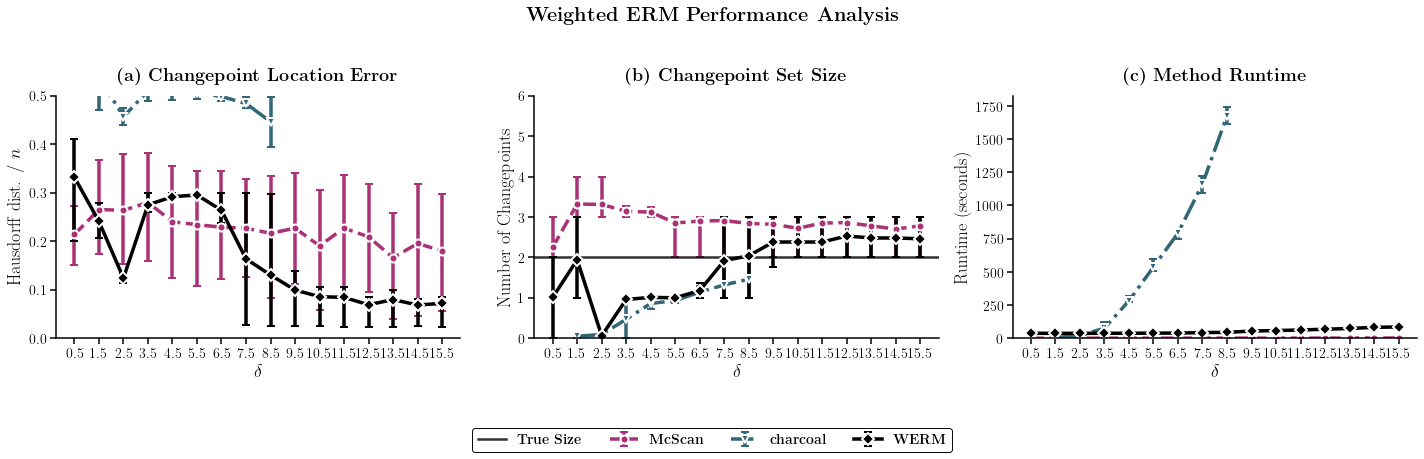

2. Confidence bands (publication style)...


/tmp/ipykernel_310898/1368123670.py:169: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/scratch/ga442/miniforge3/envs/weighted-erm/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


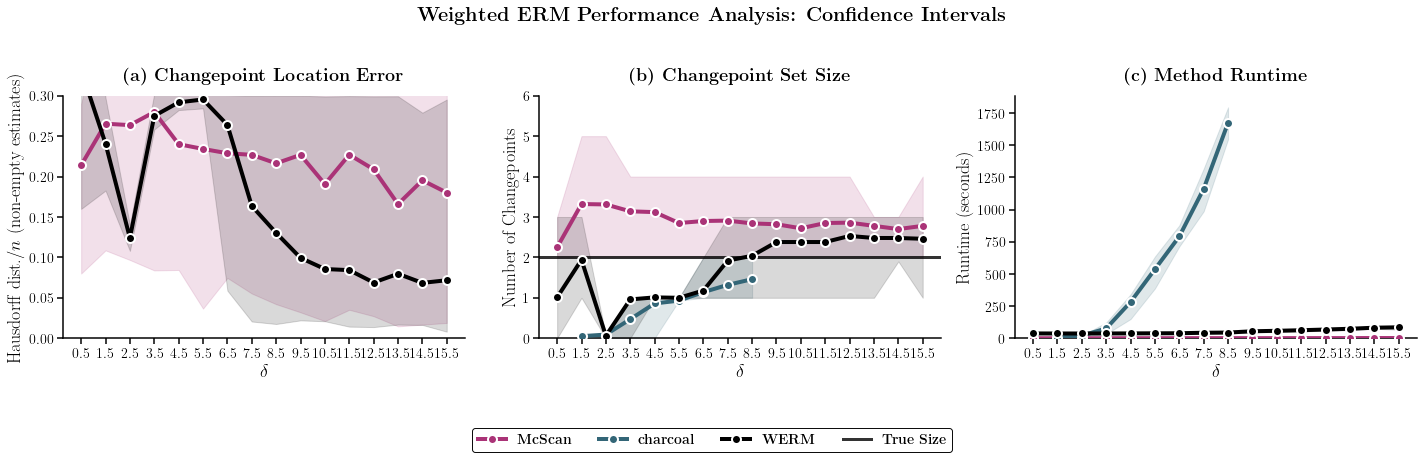

3. Box plots with deterministic raw-point jitter (M3 final setup)...


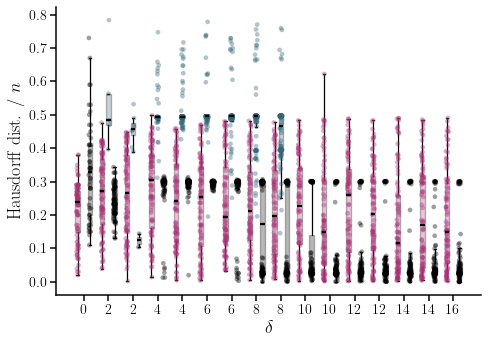

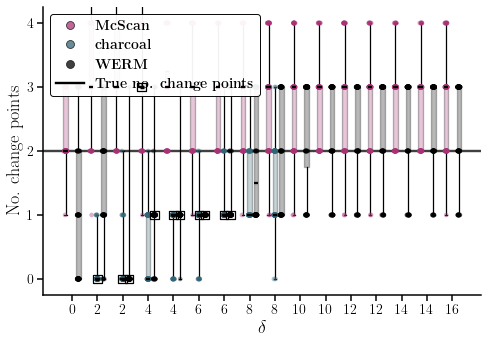

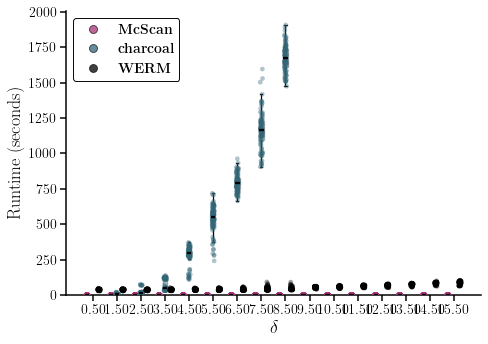

4. Enhanced changepoint histograms (publication style)...


/tmp/ipykernel_310898/1368123670.py:995: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.97])


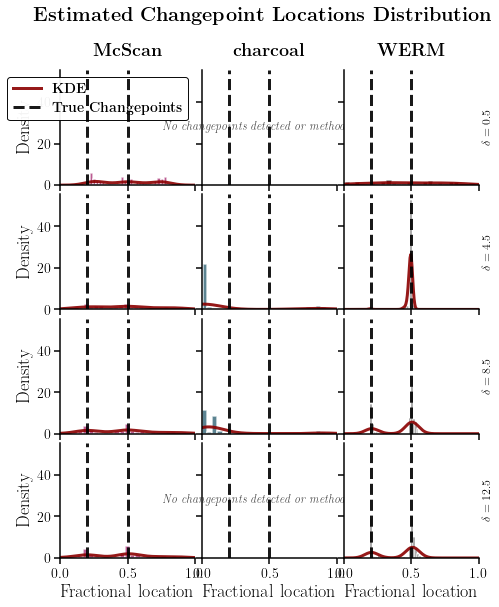

Plots complete; experiment artifact was not modified.


In [2]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

SMOKE_MODE = os.environ.get("WERM_SMOKE") == "1"
FINAL_RESULT_FILE = "results/M2_upsample_final_alpha03_seed42_100trials.pkl"
if SMOKE_MODE:
    FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace(".pkl", "_smoke.pkl")
with open(FINAL_RESULT_FILE, "rb") as handle:
    _payload = pickle.load(handle)
results = _payload["results"]
_params = _payload["params"]
p, L = _params["p"], _params["L"]
delta_list = np.asarray(_params["delta_list"])
fixed_noise_scale = _params["fixed_noise_scale"]
num_trials = _params["num_trials"]
fractional_chgpt_locations = np.asarray(_params["fractional_chgpt_locations"])
random_seed = _params["random_seed"]
CHARCOAL_MAX_DELTA = _params.get("charcoal_max_delta", 9.0)
methods_to_evaluate = _params["methods_evaluated"]
method_names_list = [method["name"] for method in methods_to_evaluate]
print(f"Loaded {FINAL_RESULT_FILE}")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})


# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Set all infs to NaN for plotting
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        # Using np.nanmean to ignore NaNs in the calculation
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Hausdorff dist. / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            print(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=14, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff dist./$n$ (non-empty estimates)', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                print(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(delta_list, p10, p90, color=plot_colors[method_idx], # Changed x-axis to delta_list
                            alpha=0.15, zorder=1)
            ax.plot(delta_list, means, color=plot_colors[method_idx], linewidth=4, # Changed x-axis to delta_list
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(delta_list) # Changed x-ticks
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=14, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

x_y_label_fontsize = 18

# --- Distribution Plotting Functions -----------------------------------------
#
# Three display modes are supported:
#   1. "box_jitter"      : standard boxplot + all observations (recommended)
#   2. "interval_jitter" : 5--95%, IQR, median + all observations
#   3. "violin_jitter"   : violin + IQR/median + all observations
#
# A box with Q1 == Q3 is statistically supposed to collapse.  We therefore do
# not artificially change its quartiles.  Instead, collapsed IQRs are reinforced
# with a thick horizontal line and, optionally, a hollow-square glyph.

from matplotlib.lines import Line2D


_DISTRIBUTION_STYLES = {"box_jitter", "interval_jitter", "violin_jitter"}
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}


def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.38,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_summary(
    ax,
    position,
    color,
    summary,
    box_width,
    collapsed_style,
):
    """Draw 5--95%, IQR, and median summaries."""
    cap_half_width = 0.14 * box_width

    # Thin 5--95% interval and end caps.
    ax.vlines(
        position,
        summary["q05"],
        summary["q95"],
        color="black",
        linewidth=1.35,
        zorder=5,
    )
    ax.hlines(
        [summary["q05"], summary["q95"]],
        position - cap_half_width,
        position + cap_half_width,
        color="black",
        linewidth=1.35,
        zorder=5,
    )

    # Thick IQR interval. It correctly becomes a point/line when IQR=0.
    ax.vlines(
        position,
        summary["q25"],
        summary["q75"],
        color=color,
        linewidth=8.0,
        alpha=0.58,
        zorder=5,
    )

    # Median remains visible even when every interval collapses.
    ax.scatter(
        [position],
        [summary["median"]],
        marker="D",
        s=46,
        facecolor=color,
        edgecolor="black",
        linewidth=0.9,
        zorder=7,
        label="_nolegend_",
    )

    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )


def _draw_interval_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw raw observations together with quantile intervals and the median."""
    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _draw_violin_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """
    Draw a violin/raincloud-style display plus points and quantile summaries.

    The violin is omitted when there are fewer than two distinct observations,
    because a kernel density is then undefined/uninformative.
    """
    if values.size >= 2 and summary["n_unique"] >= 2:
        parts = ax.violinplot(
            [values],
            positions=[position],
            widths=1.15 * box_width,
            showmeans=False,
            showmedians=False,
            showextrema=False,
            points=100,
            bw_method="scott",
        )
        body = parts["bodies"][0]
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.0)
        body.set_alpha(0.20)
        body.set_zorder(1)

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )
    _draw_interval_summary(
        ax=ax,
        position=position,
        color=color,
        summary=summary,
        box_width=box_width,
        collapsed_style=collapsed_style,
    )


def _format_distribution_diagnostic(metric_label, method_name, delta, summary):
    return (
        f"{metric_label}; method={method_name}; delta^2={delta:g}: "
        f"n={summary['n']}, unique={summary['n_unique']}, "
        f"min={summary['min']:.3g}, Q1={summary['q25']:.3g}, "
        f"median={summary['median']:.3g}, Q3={summary['q75']:.3g}, "
        f"max={summary['max']:.3g}, IQR={summary['iqr']:.3g}, "
        f"collapsed={summary['collapsed']}"
    )


def _plot_grouped_distributions(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    metric_prefix,
    metric_label,
    y_label,
    filename_base,
    filename_metric,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    random_seed=2026,
    box_width=0.72,
    jitter_width=0.20,
    point_size=22,
    point_alpha=0.38,
    diagnostics=False,
    show_legend=True,
    legend_loc="upper left",
    y_limits=None,
    y_ticks=None,
    reference_y=None,
    reference_label=None,
    x_label=r'$\delta$',
    tick_label_format=".0f",
):
    """Shared implementation for location, size, and runtime distributions."""
    if plot_style not in _DISTRIBUTION_STYLES:
        raise ValueError(
            f"plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, "
            f"got {plot_style!r}."
        )
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    rng = np.random.default_rng(random_seed)

    plot_labels = [method["label"] for method in methods_to_evaluate]
    plot_colors = [method["color"] for method in methods_to_evaluate]
    methods = [method["name"] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    diagnostic_records = []

    for delta_idx, delta in enumerate(current_delta_list):
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f"{metric_prefix}_{method_name}")
            if data is None or data.ndim < 2 or data.shape[0] <= delta_idx:
                _warn(
                    f"No {metric_label} data for {method_name} at "
                    f"delta^2={delta:g}; skipping this group."
                )
                continue

            values = _finite_1d(data[delta_idx, :])
            if values.size == 0:
                _warn(
                    f"No finite {metric_label} observations for {method_name} "
                    f"at delta^2={delta:g}; skipping this group."
                )
                continue

            summary = _distribution_summary(values)
            position = delta_idx * spacing + method_idx
            color = plot_colors[method_idx]

            record = {
                "metric": metric_label,
                "method": method_name,
                "delta_value": float(delta),
                **summary,
            }
            diagnostic_records.append(record)
            if diagnostics:
                print(
                    _format_distribution_diagnostic(
                        metric_label, method_name, delta, summary
                    )
                )

            draw_kwargs = dict(
                ax=ax,
                values=values,
                position=position,
                color=color,
                rng=rng,
                summary=summary,
                box_width=box_width,
                jitter_width=jitter_width,
                point_size=point_size,
                point_alpha=point_alpha,
                collapsed_style=collapsed_style,
            )

            if plot_style == "box_jitter":
                _draw_box_jitter_group(**draw_kwargs)
            elif plot_style == "interval_jitter":
                _draw_interval_jitter_group(**draw_kwargs)
            else:
                _draw_violin_jitter_group(**draw_kwargs)

    # Optional horizontal truth/reference line.
    if reference_y is not None:
        ax.axhline(
            y=reference_y,
            color="black",
            linestyle="-",
            linewidth=2.4,
            alpha=0.75,
            zorder=0,
            label="_nolegend_",
        )

    delta_positions = [
        i * spacing + (len(methods) - 1) / 2
        for i in range(len(current_delta_list))
    ]
    ax.set_xticks(delta_positions)
    ax.set_xticklabels(
        [format(float(k), tick_label_format) for k in current_delta_list]
    )
    ax.set_xlabel(x_label, fontsize=18)
    ax.set_ylabel(y_label, fontsize=18)

    if y_limits is not None:
        ax.set_ylim(*y_limits)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markersize=8,
                markerfacecolor=plot_colors[i],
                markeredgecolor="black",
                markeredgewidth=0.8,
                alpha=0.75,
                label=plot_labels[i],
            )
            for i in range(len(methods))
        ]
        if reference_y is not None and reference_label is not None:
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color="black",
                    linewidth=2.4,
                    label=reference_label,
                )
            )
        ax.legend(
            handles=legend_elements,
            loc=legend_loc,
            fontsize=14,
            frameon=True,
            edgecolor="black",
            framealpha=0.95,
        )

    ax.tick_params(
        axis="both",
        which="major",
        width=1.5,
        length=6,
        labelsize=14,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    # Keep the historical filenames for the recommended box+jitter mode.
    style_suffix = {
        "box_jitter": "boxplots",
        "interval_jitter": "interval_jitter",
        "violin_jitter": "violin_jitter",
    }[plot_style]
    output_stem = f"{filename_base}_{filename_metric}_{style_suffix}"

    fig.tight_layout()



    plt.show()

    return fig, ax, diagnostic_records


def plot_location_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot the Hausdorff-error distributions.

    Recommended publication mode: plot_style="box_jitter".
    Clean alternative:             plot_style="interval_jitter".
    """
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="haus",
        metric_label="Hausdorff distance / n",
        y_label=r'Hausdorff dist. / $n$',
        filename_base=filename_base,
        filename_metric="location",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=False,
        tick_label_format=".0f",
        x_label=r'$\delta$',
    )


def plot_size_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    L,
    fractional_chgpt_locations,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """
    Plot estimated changepoint counts.

    Because this response is discrete, box+jitter or interval+jitter is preferable
    to a violin plot, whose kernel smoothing can imply nonexistent values.
    """
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="size",
        metric_label="Number of change points",
        y_label=r'No. change points',
        filename_base=filename_base,
        filename_metric="size",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(-0.25, L + 0.25),
        y_ticks=np.arange(0, L + 1, dtype=int),
        reference_y=len(fractional_chgpt_locations),
        reference_label=r'\textbf{True no. change points}',
        tick_label_format=".0f",
        x_label=r'$\delta$',
    )


def plot_runtime_boxplots(
    current_delta_list,
    current_results,
    methods_to_evaluate,
    filename_base,
    plot_style="box_jitter",
    collapsed_style="line_and_marker",
    diagnostics=False,
):
    """Plot runtime distributions using any supported display mode."""
    return _plot_grouped_distributions(
        current_delta_list=current_delta_list,
        current_results=current_results,
        methods_to_evaluate=methods_to_evaluate,
        metric_prefix="runtime",
        metric_label="Runtime (seconds)",
        y_label=r'Runtime (seconds)',
        filename_base=filename_base,
        filename_metric="runtime",
        plot_style=plot_style,
        collapsed_style=collapsed_style,
        diagnostics=diagnostics,
        show_legend=True,
        legend_loc="upper left",
        y_limits=(0, None),
        tick_label_format=".2f",
        x_label=r'$\delta$',
    )


# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_delta_idx = list(range(len(delta_list)))[::4]
    selected_deltas = delta_list[::4]
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(2.5 * len(methods_to_plot_names), 2.2 * len(selected_deltas)),
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08})

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    # Use the fixed_noise_scale defined globally
    global fixed_noise_scale # Access the global fixed_noise_scale

    for row, (delta_idx, delta_val) in enumerate(zip(selected_delta_idx, selected_deltas)):
        n = int(delta_val * p) # n depends on delta, which is now the varying parameter
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                         color=method_plotting_info[method_name]['color'],
                         density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                         transform=ax.transAxes, ha='center', va='center',
                         fontsize=12, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                                 alpha=0.9, zorder=10,
                                 label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel('Fractional location', fontsize=18)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=18)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\delta = {delta_val}$', transform=ax.transAxes, # Changed to delta
                                 rotation=90, verticalalignment='center', fontsize=12,
                                 fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=14, frameon=True,
                                         edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
# Final M1b plotting format: Tol-bright competitors and black hero WERM.
_FINAL_M1B_STYLES = {
    'McScan': dict(label=r'\textbf{McScan}', color='#AA3377', marker='o', linestyle='--', linewidth=1.5, zorder=5),
    'charcoal': dict(label=r'\textbf{charcoal}', color='#336677', marker='v', linestyle='-.', linewidth=1.5, zorder=5),
    'WERM-unp-10fold': dict(label=r'\textbf{WERM}', color='black', marker='D', linestyle='-', linewidth=2.5, zorder=10),
}
for _method in methods_to_evaluate:
    _method.update(_FINAL_M1B_STYLES.get(_method['name'], {}))
PAL = [_method['color'] for _method in methods_to_evaluate]

print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots with deterministic raw-point jitter (M3 final setup)...")
plot_location_boxplots(
    delta_list, results, methods_to_evaluate, "M2_upsample_final",
    plot_style="box_jitter", collapsed_style="line_and_marker",
)
plot_size_boxplots(
    delta_list, results, methods_to_evaluate, L, fractional_chgpt_locations,
    "M2_upsample_final", plot_style="box_jitter",
    collapsed_style="line_and_marker",
)
plot_runtime_boxplots(
    delta_list, results, methods_to_evaluate, "M2_upsample_final",
    plot_style="box_jitter", collapsed_style="line_and_marker",
)
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, method_names_list)

print('Plots complete; experiment artifact was not modified.')


## Canonical M2 Comparison Experiment plots

The exact final plotting format from `M2 Comparison Experiments.ipynb`, including its delta subsampling and histogram setup.

<>:429: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:429: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?


Removing 105 matplotlib modules...
Successfully set backend to: pgf
main_logger not defined, skipping logging.
Using palette: ['#AA3377', '#336677', 'black'] (Paul Tol Vibrant)
Data loaded/dummy data created for plotting.
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...
1. Asymmetric error bars (publication style) - location
labels b4:  ['McScan', 'charcoal', '\\textbf{WERM}']
labels after:  ['McScan', 'charcoal', '\\textbf{WERM}']
data for McScan before inf handling:  [[0.21       0.2        0.27       ... 0.29       0.14       0.02      ]
 [0.41666667 0.38666667 0.41666667 ... 0.34       0.06666667 0.26666667]
 [0.288      0.07       0.076      ... 0.336      0.246      0.308     ]
 ...
 [0.02851852 0.29222222 0.17407407 ... 0.38296296 0.04       0.02666667]
 [0.31       0.37241379 0.32758621 ... 0.01344828 0.33827586 0.01172414]
 [0.0283871  0.37064516 0.45225806 ... 0.06       0.01903226 0.06612903]]
data for charcoal before inf handling:  [[     

/tmp/ipykernel_310898/3425847061.py:429: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location':
/tmp/ipykernel_310898/3425847061.py:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location' and plot_type is not 'size':
/tmp/ipykernel_310898/3425847061.py:435: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location' and plot_type is not 'size':
/tmp/ipykernel_310898/3425847061.py:315: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data_effective, axis=1)
/tmp/ipykernel_310898/3425847061.py:267: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/scratch/ga442/miniforge3/envs/weighted-erm/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


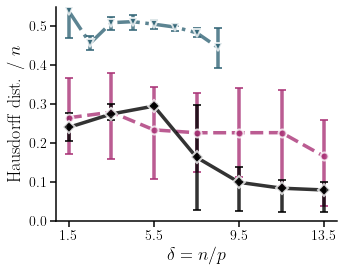

1. Asymmetric error bars (publication style) - size
labels b4:  ['McScan', 'charcoal', '\\textbf{WERM}']
labels after:  ['McScan', 'charcoal', '\\textbf{WERM}']


/tmp/ipykernel_310898/3425847061.py:358: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data_effective, axis=1)
/tmp/ipykernel_310898/3425847061.py:267: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/scratch/ga442/miniforge3/envs/weighted-erm/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


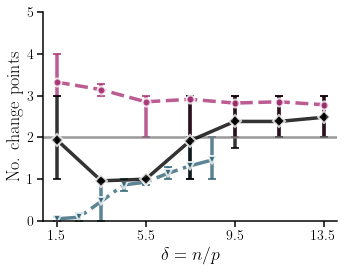

1. Asymmetric error bars (publication style) - runtime
labels b4:  ['McScan', 'charcoal', '\\textbf{WERM}']
labels after:  ['McScan', 'charcoal', '\\textbf{WERM}']


/tmp/ipykernel_310898/3425847061.py:401: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data_effective, axis=1)


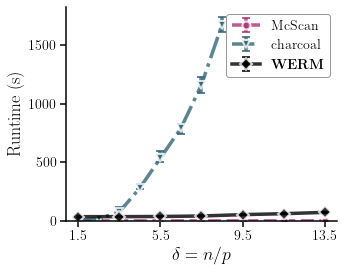

2. Confidence bands (publication style)...


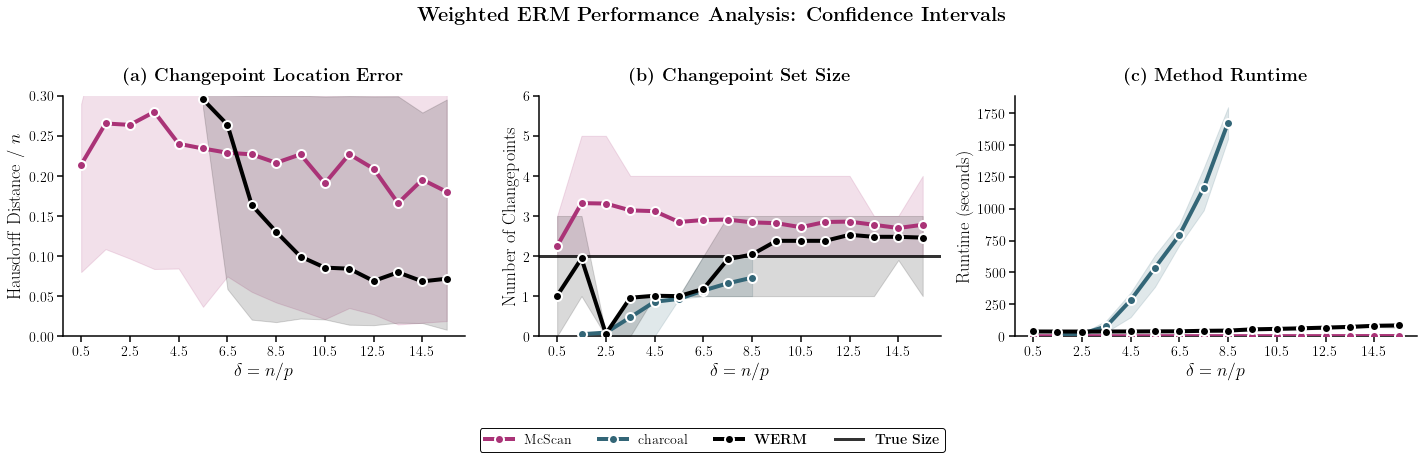

3. Box plots (publication style)...


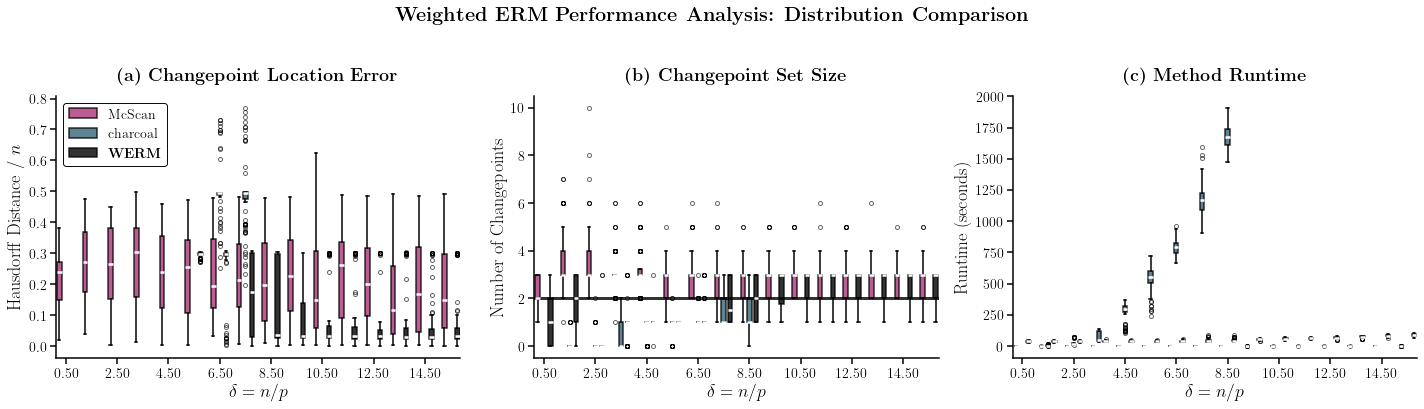

4. Enhanced changepoint histograms (publication style)...


/tmp/ipykernel_310898/3425847061.py:754: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96])


Publication-ready plotting completed in 3.57 seconds


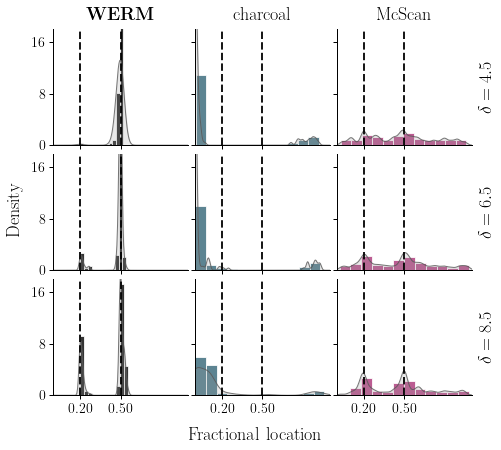

In [3]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

methods_to_evaluate = [


    # --- COMPETITORS (TOL-BRIGHT) ---
    # Optimized for distinctness AND safety.
    
    # # 1. Purple: Very distinct from Black and usually pops well.
    {
        'name': 'McScan', 
        'label': 'McScan', 
        'color': '#AA3377', # Purple
        'marker': 'o', 
        'linestyle': '--', 
        'linewidth': 1.5, 
        'zorder': 5
    },
    # # 2. Green: The color you were missing in previous palettes. 
    # # This specific green (#228833) is dark enough to be safe against red.
    # {
    #     'name': 'MOSEG', 
    #     'label': 'MOSEG', 
    #     'color': '#228833', # Green
    #     'marker': '^', 
    #     'linestyle': '-.', 
    #     'linewidth': 1.5, 
    #     'zorder': 5
    # },
    # # 3. Blue: Standard strong blue.
    # {
    #     'name': 'DPDU', 
    #     'label': 'DPDU', 
    #     'color': '#4477AA', # Blue
    #     'marker': 'D', 
    #     'linestyle': ':', 
    #     'linewidth': 1.5, 
    #     'zorder': 5
    # },
    # # # 4. Red: A softer red that doesn't vibrate against the green.
    # {
    #     'name': 'DCDP', 
    #     'label': 'DCDP', 
    #     'color': '#EE6677', # Red
    #     'marker': 's', 
    #     'linestyle': '--', 
    #     'linewidth': 1.5, 
    #     'zorder': 5
    # },
    # 5. Cyan: High lightness, creates good contrast with the darker colors above.
    {
        'name': 'charcoal', 
        'label': 'charcoal', 
        # 'color': '#66CCEE', # Cyan
        'color': '#336677', # Darker than cyan
        'marker': 'v', 
        'linestyle': '-.', 
        'linewidth': 1.5, 
        'zorder': 5
    },
    # # 6. Yellow/Gold: Used last as it is hardest to see on white paper.
    # # Note: We use a darker gold-yellow to ensure visibility.
    # {
    #     'name': 'GLMBSA', 
    #     'label': 'GLMBSA', 
    #     'color': '#E69F00', # Yellow/Gold
    #     'marker': 'p', 
    #     'linestyle': ':', 
    #     'linewidth': 1.5, 
    #     'zorder': 5
    # },

    
     # --- PROPOSED METHOD (HERO) ---
    # Black is used as the anchor. It has the highest contrast against white paper.
    # {
    #     'name': 'WERM', 
    #     'label': r'\textbf{WERM}', 
    #     'color': 'black', 
    #     'marker': '*', 
    #     'linestyle': '-', 
    #     'linewidth': 2.5, 
    #     'zorder': 10
    # },
    {
        'name': 'WERM-unp-10fold', 
        'label': r'\textbf{WERM}', 
        'color': 'black', 
        'marker': 'D', 
        'linestyle': '-', 
        'linewidth': 2.5, 
        'zorder': 10
    },
    # {
    #     'name': 'WERM-CV', 
    #     'label': r'\textbf{WERM}', 
    #     'color': 'black', 
    #     'marker': '*', 
    #     'linestyle': '-', 
    #     'linewidth': 2.5, 
    #     'zorder': 10
    # },   

]

method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
PAL = [method['color'] for method in methods_to_evaluate]

# KDE / Histogram Context Style
kde_style = {
    'color': '#555555',       # Dark Grey line for definition
    'linestyle': '-',         # Solid line (distinct from competitor dashes)
    'linewidth': 1.0,         # Thinner than your methods (1.0 vs 1.5/2.5)
    'alpha': 0.8,             # Slight transparency for the line itself
    'fill_color': '#999999',  # Lighter grey for the area
    'fill_alpha': 0.2         # Very transparent fill
}

# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------
import importlib
import sys
import numpy as np # Make sure numpy is imported
import time # Make sure time is imported
import matplotlib # Make sure matplotlib is imported
import gc
from scipy.stats import gaussian_kde # For KDE in histograms
import matplotlib.pyplot as plt
import random
import pickle
from KDEpy import FFTKDE
from kde_diffusion import kde1d
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV


# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Assuming `main_logger` is defined elsewhere in your script or you can remove this line
try:
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()


# random.shuffle(PAL)

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data and set up global parameters (moved from end to top for clarity) ---
# This part assumes you have a filename to load from, or you'll need to define
# `results`, `params`, `p`, `L`, `noise_std`, `δ_list`, `fractional_chgpt_locations`,
# `n_jobs`, `methods_to_evaluate`, `random_seed` directly or load them differently.

# Example of how to load the data (adjust filename as needed)
# You need to ensure the `results` dictionary and `params` are populated
# before calling the plotting functions.
try:
    # This filename needs to match your saved results
    # For the example, I'll use the one provided in the original code.
    # Replace with your actual filename if different.
    # _example_filename = 'results/M2_varydelta_alpha03_cp0205_McScan_charcoal_WERM-unp_results_p200_L4_delta012345678_noisecale0.316_seed42.pkl'
    _example_filename = 'results/M2_upsample_final_alpha03_seed42_100trials.pkl'
    with open(_example_filename, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['fixed_noise_scale'] # Changed to fixed_noise_scale
    δ_list = params['delta_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', None)

    # Extract method names for plotting
    method_names_list = [method['name'] for method in methods_to_evaluate]

except FileNotFoundError:
    print(f"Warning: Results file '{_example_filename}' not found. Please ensure your results are saved or define `results` and `params` directly for plotting.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 100
    L = 3
    noise_std = 0.5
    δ_list = np.array([1, 2, 3, 4, 5, 6])
    fractional_chgpt_locations = [0.2, 0.5, 0.8]
    num_trials = 10
    n_jobs = 1
    # Dummy methods_to_evaluate based on original code's 'simple', 'ext', 'elbow', 'kneedle'
    methods_to_evaluate = [
        {'name': 'simple', 'label': r'\textbf{Full Prior}'},
        {'name': 'ext', 'label': r'\textbf{Location Prior}'},
        {'name': 'elbow', 'label': r'\textbf{Extended Elbow}'},
        {'name': 'kneedle', 'label': r'\textbf{Kneedle}'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Populate dummy results
    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            # Generate random data for dummy results
            if metric == 'chgpts':
                results[key] = []
                for delta_idx in range(len(δ_list)):
                    for _ in range(num_trials):
                        # Generate some dummy changepoints, vary by delta_idx
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        dummy_chgpts = np.random.rand(num_chgpts_detected) * (delta_idx / 5 + 0.5) # Example variation
                        results[key].append((delta_idx, dummy_chgpts * p * δ_list[delta_idx])) # Scale to n
            else:
                results[key] = np.random.rand(len(δ_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05

print("Data loaded/dummy data created for plotting.")

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------

x_y_label_fontsize = 18

# Calculate percentiles for asymmetric error bars
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

def plot_with_asymmetric_errors_publication(plot_type='all'):
    """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
    if plot_type == 'all':
        fig, axs = plt.subplots(1, 3, figsize=(20, 6))
        fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
    else:
        fig, axs = plt.subplots(1, 1, figsize=(5.0, 4.0))
    
    # Use method_names_list from the loaded/generated params
    methods = method_names_list
    colors = PAL[:len(methods)] # Use as many colors as methods
    
    # Define markers and linestyles to match the number of methods
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
    labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
    print("labels b4: ", labels)
    # labels = ['\\textbf{McScan}', '\\textbf{MOSEG}', '\\textbf{WERM}']
    # labels = ['McScan', 'MOSEG', 'WERM']
    print("labels after: ", labels)
    
    # Hausdorff Distance Plot
    if plot_type == 'all' or plot_type == 'location':
        if plot_type == 'all': ax = axs[0]
        elif plot_type == 'location': ax = axs

        for i, method_name in enumerate(methods):
            data = results[f'haus_{method_name}']
            if method_name == 'charcoal':
                skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            else:
                skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            end_idx = -2
            data_effective = data[start_idx:end_idx:skip_factor]
            delta_effective = δ_list[start_idx:end_idx:skip_factor]
            # Set all infs to NaN for plotting
            print(f"data for {method_name} before inf handling: ", data)
            data_effective = np.where(np.isinf(data_effective), np.nan, data_effective)
            means = np.nanmean(data_effective, axis=1)
            errors = get_asymmetric_errors(data_effective)

            # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
            means = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, means)
            errors = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, errors)
            
            ax.errorbar(delta_effective, means, yerr=errors,
                        label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.8)
        
        ax.set_ylim((0, 0.55))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Hausdorff dist. / $n$', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        
        # Cleaner x-axis with fewer ticks
        ax.set_xticks(delta_effective[::2])  # Show every other tick
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Changepoint Set Size Plot
    if plot_type == 'all' or plot_type == 'size':
        if plot_type == 'all': ax = axs[1]
        elif plot_type == 'size': ax = axs

        for i, method_name in enumerate(methods):
            if method_name == 'charcoal':
                skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            else:
                skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            end_idx = -2
            data = results[f'size_{method_name}']
            data_effective = data[start_idx:end_idx:skip_factor]
            delta_effective = δ_list[start_idx:end_idx:skip_factor]
            means = np.nanmean(data_effective, axis=1)
            errors = get_asymmetric_errors(data_effective)

            # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
            means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
            errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)

            ax.errorbar(delta_effective, means, yerr=errors,
                        label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.8)
        
        ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
                   linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        ax.set_ylim((0, L + 1))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'No. change points', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        
        ax.set_xticks(delta_effective[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Runtime Plot
    if plot_type == 'all' or plot_type == 'runtime':
        if plot_type == 'all': ax = axs[2]
        elif plot_type == 'runtime': ax = axs
        for i, method_name in enumerate(methods):
            if method_name == 'charcoal':
                skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            else:
                skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                start_idx = 1 # Start from index 1 to avoid the very first point if needed
            end_idx = -2
            data = results[f'runtime_{method_name}']
            data_effective = data[start_idx:end_idx:skip_factor]
            delta_effective = δ_list[start_idx:end_idx:skip_factor]
            means = np.nanmean(data_effective, axis=1)
            errors = get_asymmetric_errors(data_effective)

            # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
            means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
            errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)
            
            ax.errorbar(delta_effective, means, yerr=errors,
                        label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
        
        ax.set_ylim(bottom=0)
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Runtime (s)', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        
        ax.set_xticks(delta_effective[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    if plot_type == 'all':
        # Single legend for all subplots
        handles, labels_leg = axs[1].get_legend_handles_labels()
        if plot_type is not 'location':
            fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                    ncol=len(methods)+1, fontsize=14, frameon=True,
                    edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    else:
        if plot_type is not 'location' and plot_type is not 'size':
            ax.legend(loc='best', prop={'size': 14}, fancybox = True, framealpha = 0.4)
        fig.tight_layout()
    
    # plt.show() # Removed plt.show() as per the original structure that saves then shows
    return fig, axs

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]
    
    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        
        for method_idx, method_name in enumerate(methods):
            data = results[f'{metric}_{method_name}']
            means = np.mean(data, axis=1)
            
            # Calculate confidence intervals (10th and 90th percentiles)
            p10 = np.percentile(data, 10, axis=1)
            p90 = np.percentile(data, 90, axis=1)
            
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)
            
            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)
            
            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
        
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=14, frameon=True,
               edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]
    
    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        
        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            
            for method_idx, method_name in enumerate(methods):
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                box_data.append(data)
                box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
                box_colors.append(colors[method_idx])
            
            # Create publication-ready box plots
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            
            # Color the boxes
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')
        
        # Set x-axis labels - only show every other delta for cleanliness
        # Adjust delta_positions calculation
        delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.2f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Add legend (only for first subplot)
        if ax_idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=labels[i])
                               for i in range(len(methods))]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                      frameon=True, edgecolor='black', framealpha=0.95)
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
        
        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms (Optimized Layout)
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
    """
    Publication-ready changepoint location histograms with tight layout
    """
    
    # 1. Setup Data
    method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
    method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
    current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
    current_method_names = [method['name'] for method in current_methods]

    # Reverse order as per original request
    method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)}
    method_colors_map = {k: method_colors_map[k] for k in reversed(method_colors_map)}
    current_methods = list(reversed(current_methods))
    current_method_names = list(reversed(current_method_names))

    selected_deltas_idx = list(range(len(δ_list)))[4:9:2]
    selected_deltas = δ_list[4:9:2]
    
    num_rows = len(selected_deltas)
    num_cols = len(current_methods)

    # 2. Setup Figure - TIGHTER DIMENSIONS
    # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
    # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(2.5 * num_cols, 2.2 * num_rows), 
                             sharex=True, sharey=True,
                             gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
    # Handle single subplot cases to ensure axes is always 2D array
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_cols == 1:
        axes = axes.reshape(-1, 1)
    elif num_rows == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')

    # 3. Plotting Loop
    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # --- Data Collection (Same as original) ---
            all_chgpts = []
            chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
            for res_delta_idx, chgpts_list in chgpts_data_for_method:
                if res_delta_idx == delta_idx:
                    for chgpts in chgpts_list:
                        if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                            chgpts_array = np.array(chgpts)
                            valid_chgpts = chgpts_array[chgpts_array != -1]
                            for chgpt in valid_chgpts:
                                all_chgpts.append(chgpt / n)
                        elif np.isscalar(chgpts) and chgpts != -1:
                            all_chgpts.append(chgpts / n)
            
            # --- Plotting ---
            if len(all_chgpts) > 0:
                # Histogram
                counts, bins, patches = ax.hist(all_chgpts, bins=12, alpha=0.8,
                                                color=method_colors_map[method_name],
                                                density=True, edgecolor='white',
                                                linewidth=1.0) # Thinner line for tighter look
                
                # KDE (GridSearch Logic)
                if len(all_chgpts) > 6:
                    params = {'bandwidth': np.logspace(-2, 0, 50)}
                    grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                    grid.fit(np.array(all_chgpts).reshape(-1, 1))
                    
                    x_range = np.linspace(0, 1, 200)
                    log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                    kde_values = np.exp(log_dens)
                    
                    ax.plot(x_range, kde_values, 
                            color=kde_style['color'], 
                            linewidth=kde_style['linewidth'],
                            linestyle=kde_style['linestyle'],
                            alpha=kde_style['alpha'], zorder=2)
                    
                    ax.fill_between(x_range, kde_values, 
                                    color=kde_style['fill_color'], 
                                    alpha=kde_style['fill_alpha'],
                                    zorder=1)
            else:
                ax.text(0.5, 0.5, r'\textit{N/A}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=12, alpha=0.7, style='italic')
            
            # True Changepoints
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                           linewidth=2, alpha=0.9, zorder=10,
                           label=r'\textbf{True changepoints}' if i == 0 else "")

            # --- Formatting & Ticks ---
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 18) # Enforce uniform height
            
            # Clean spines
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            
            # Custom ticks - apply to ALL, but sharex hides labels automatically
            ax.set_xticks(np.array([*fractional_chgpt_locations]))
            ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=14)
            ax.set_yticks([0, 8, 16]) # Minimal Y-ticks
            
            # Tick parameters
            # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
            ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

            # 4. Labels and Titles (Specific Locations Only)
            
            # Column Titles (Method Names) - Only Top Row
            if row == 0:
                ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=10)
            
            # Row Labels (Delta) - Right side of Last Column
            if col == num_cols - 1:
                # Use ax.text roughly in the middle right
                ax.text(1.05, 0.5, f'$\delta = {delta}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', horizontalalignment='left',
                        fontsize=18, fontweight='bold')

            # X-Axis Label - Bottom Row, Centered on Figure not Subplot
            # We skip per-subplot labels to save space
    
    # Global Labels (cleaner than per-subplot)
    fig.text(0.5, 0.01, 'Fractional location', 
             ha='center', va='bottom', fontsize=18)
    fig.text(0.04, 0.5, r'Density', 
             va='center', rotation='vertical', fontsize=18)

    # 5. Legend
    # Place one legend for the whole figure, or inside the first visible plot
    # Here we put it in the first plot, but make it compact
    first_ax = axes[0, 0]
    handles, labels = first_ax.get_legend_handles_labels()
    # if handles:
    #     # Create a legend that floats slightly inside the plot
    #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
    #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
    #     legend.set_zorder(20)

    # Final Tight Layout to handle the global labels
    # rect tuple is (left, bottom, right, top)
    plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
    return fig, axes

# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
# Save the 'all' plot separately if desired, then individual ones
# fig_all, axs_all = plot_with_asymmetric_errors_publication(plot_type='all')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
                #  dpi=300, bbox_inches='tight')
# plt.show(fig_all) # Explicitly show the figure

print("1. Asymmetric error bars (publication style) - location")
fig_loc, axs_loc = plot_with_asymmetric_errors_publication(plot_type='location')
# fig_loc.savefig(f'figures/_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Save figure with the method names and parameters in the filename
fig_loc.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_loc.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_loc)

print("1. Asymmetric error bars (publication style) - size")
fig_size, axs_size = plot_with_asymmetric_errors_publication(plot_type='size')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
fig_size.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_size.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_size)


print("1. Asymmetric error bars (publication style) - runtime")
fig_rt, axs_rt = plot_with_asymmetric_errors_publication(plot_type='runtime')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#                 dpi=300, bbox_inches='tight')
fig_rt.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_rt.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_rt)


print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
# Pass the list of method names for which you want to plot histograms.
# This will plot histograms for 'ext' (Extended Penalized ERM) only.
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)

# If you want to plot histograms for all methods evaluated, you could do:
fig_hist, axs_hist = plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
fig_hist.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf', dpi=300, bbox_inches='tight')

plotting_time = time.time() - plotting_start_time
try:
    main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")
except NameError:
    print(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# The saving of the results pickle file is handled by the first code block provided by the user.
# I've included a dummy load/setup at the top of this script to make it runnable independently for testing.
# Ensure your main execution flow calls the plotting functions after `results` and `params` are properly loaded.

## Fresh comparison: WERM+P ($\gamma=6$), WERM, charcoal, and McScan

This cell **reruns all four methods** on the original paired M2 trial data. **WERM+P** is unpenalized least-squares WERM with fixed-count candidate fits and the search penalty
$$P(K)=6\log\binom{n-1}{K-1},\qquad K\in\{1,2,3,4\}.$$
**WERM** uses the original exhaustive 10-fold count selection with absolute held-out loss, followed by a full-data refit. McScan uses automatic count estimation (`method='auto'`); charcoal uses the existing fixed threshold 10 and interval seed 42, and is applicable only through $\delta\leq9$. There is no coefficient penalty.

The four methods run on **100 trials at each of the same 10 settings**: the union of canonical curve settings $\delta=1.5,3.5,5.5,7.5,9.5,11.5,13.5$ and histogram settings $\delta=4.5,6.5,8.5$. To retain the canonical charcoal curve, charcoal alone also runs on 100 trials at $\delta=2.5$. Its intentional not-applicable status above $\delta=9$ is retained. All data generation settings, trial indices, and RNG keys remain unchanged; regenerated data hashes are checked against the original artifact. The original artifact supplies design and hashes only: **no historical method estimates are used in these plots**.

For numerical reproducibility, both WERM methods share the same fixed-count marginal weights at each sample size/count/spacing. The original marginal interpolator is used with seed 0; its results are cached within each trial and its module binding is restored afterward. This changes neither the count candidate set nor the objective. The full-data and fold weights are prepared once before timing either WERM method; this common preparation time is saved separately as `marginal_preparation_seconds`. Whenever WERM and WERM+P select the same count on a trial, their locations are required to match exactly.

The canonical plotting functions, layouts, delta selections, styles, percentile error bars, and histogram/KDE settings are retained. The four labels are **charcoal, McScan, WERM, WERM+P**. Location error is conditional on non-empty estimates, as in the canonical plots. Genuine charcoal R errors are recorded explicitly and represented as empty estimates, following the original experiment.

Run in the **weighted-erm** Python/R kernel. Checkpoints and results are isolated under `results/M2_upsample_final_WERM_plus_P_gamma6_fresh/`; figures (PNG/PDF/PGF) are under `figures/M2_upsample_final_WERM_plus_P_gamma6_fresh/`. `M2_FRESH_JOBS` controls parallelism (default 24). Only this new experiment's matching checkpoints are resumed. Original experiments, saved results, and previous gamma sweeps are retained.


Completed 1000 fresh trials for McScan, WERM, and WERM+P (gamma=6).
Completed fresh charcoal runs at all eight applicable canonical curve settings, including delta=2.5.
All regenerated data hashes matched the original trial data.
Equal-count location agreement: 322/322.
Charcoal R errors recorded as empty estimates: 4.


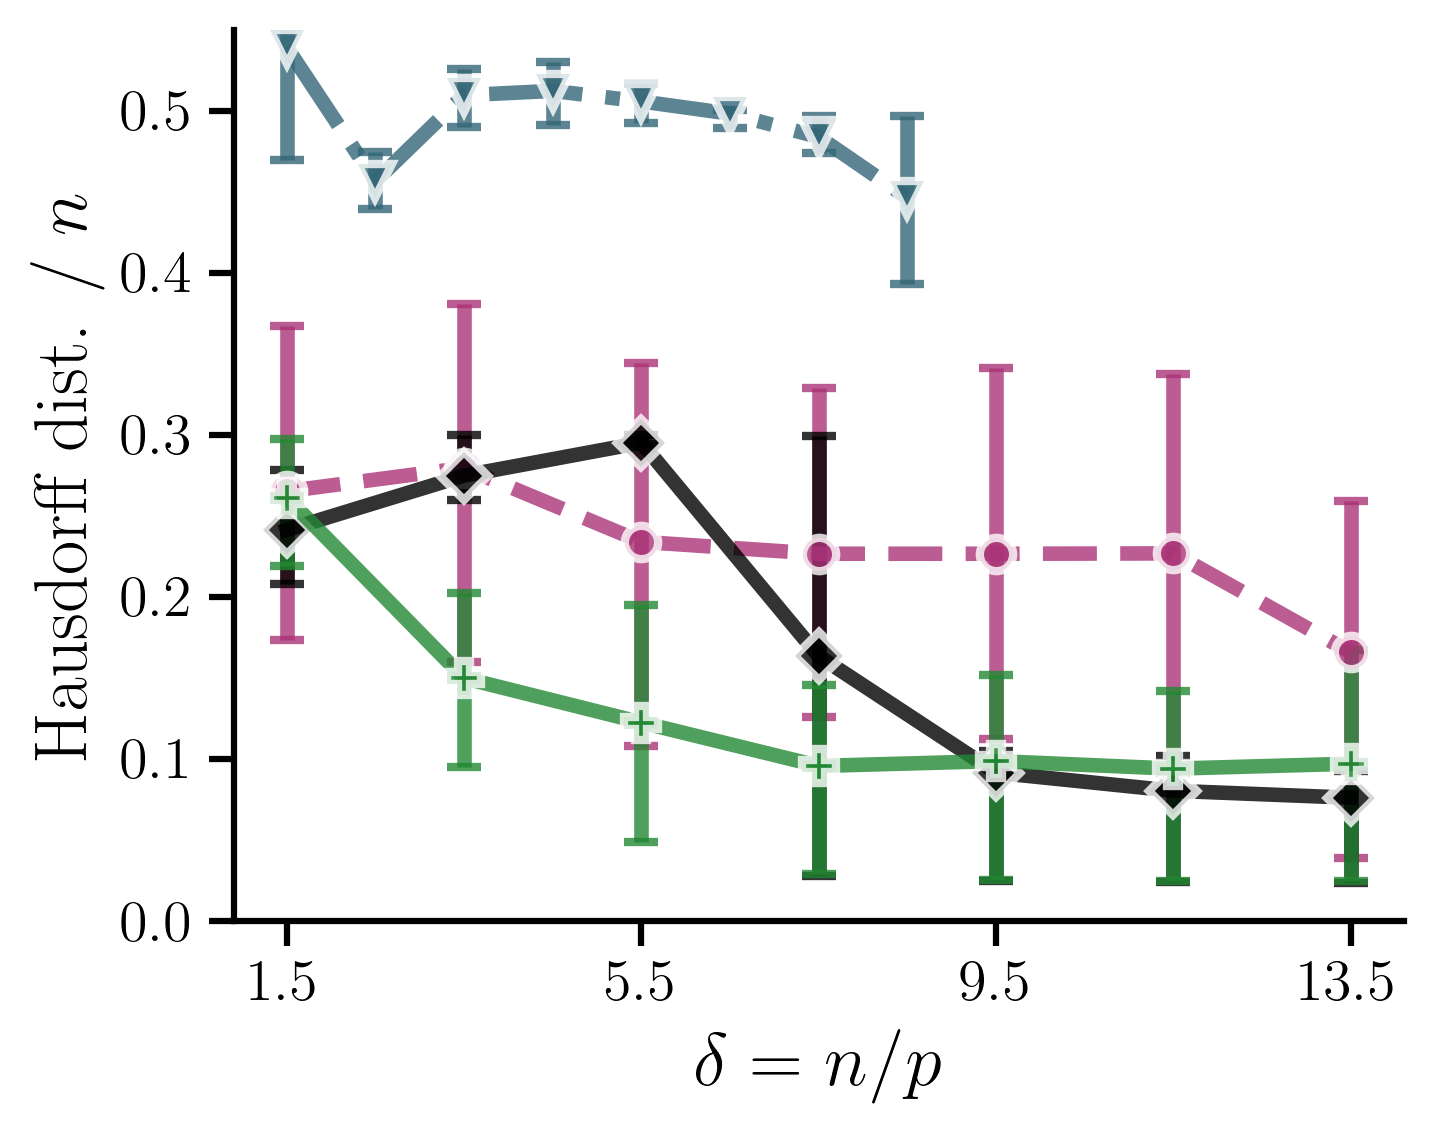

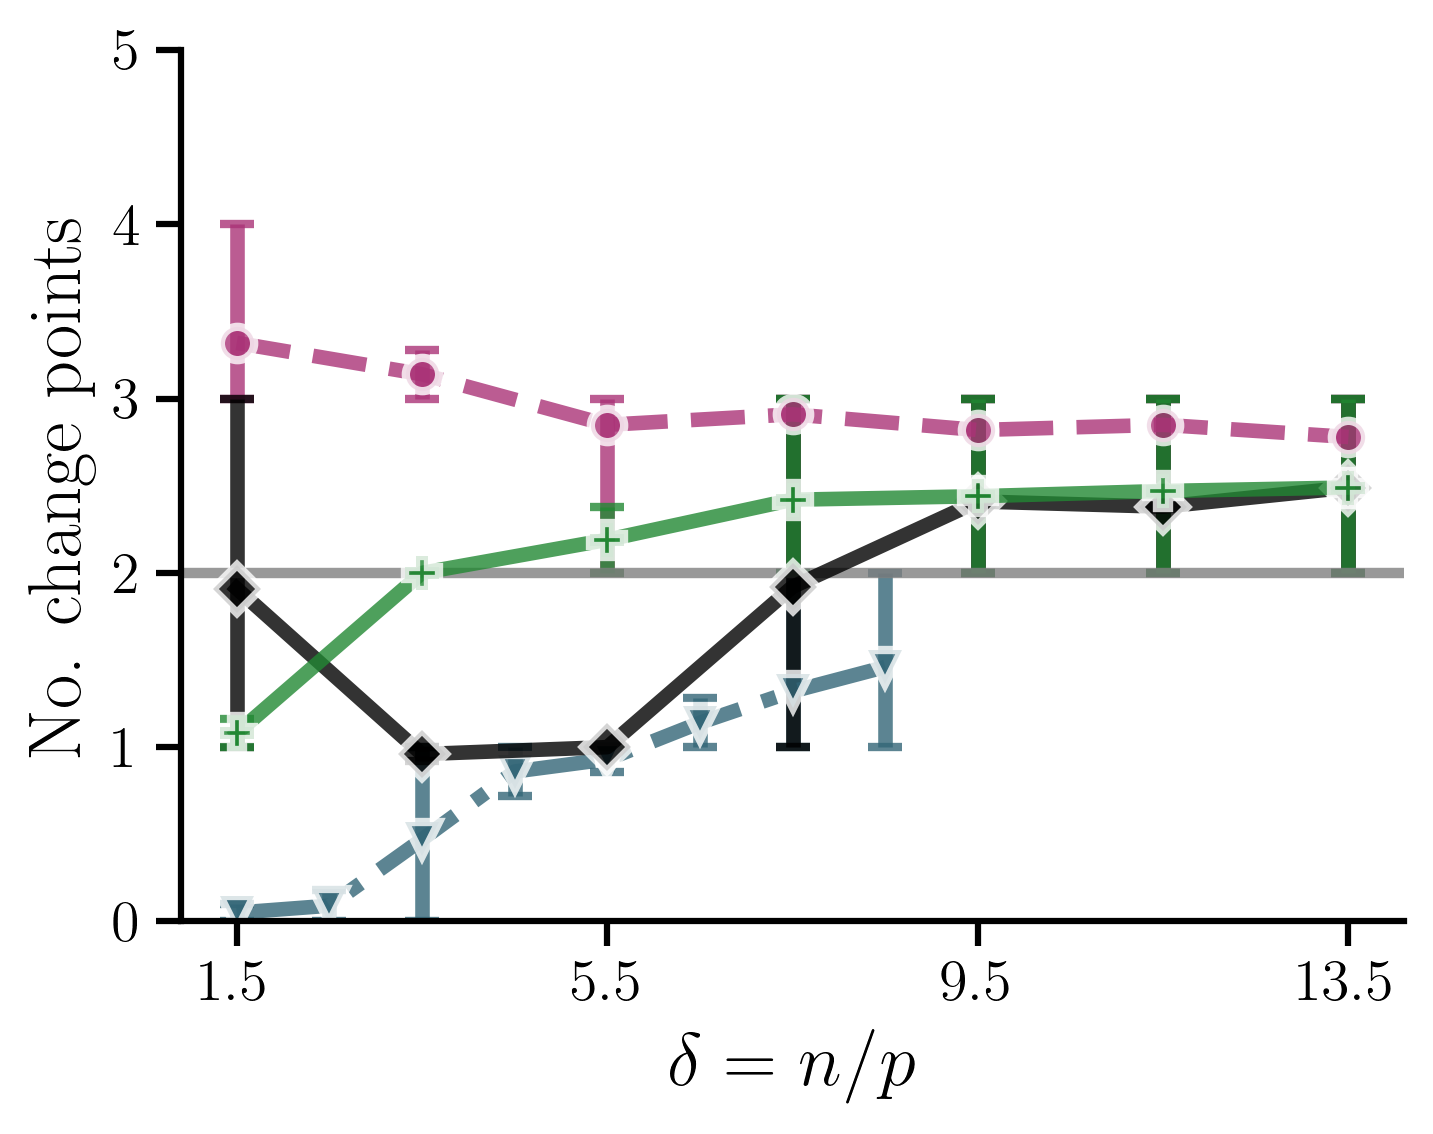

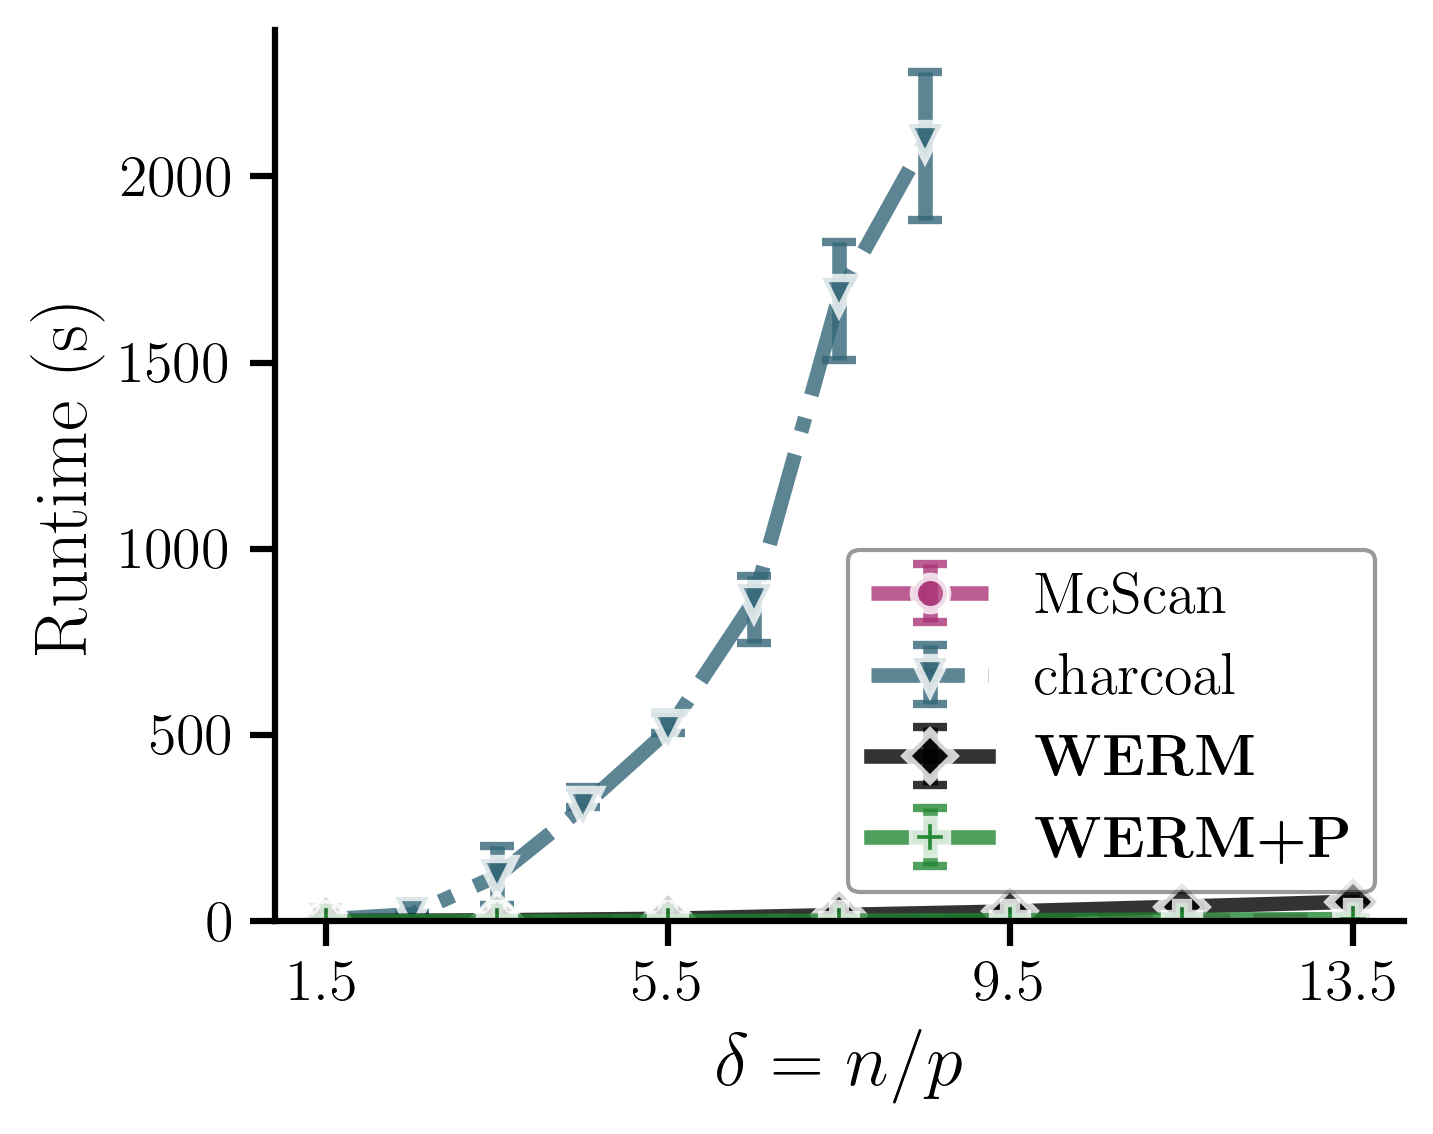

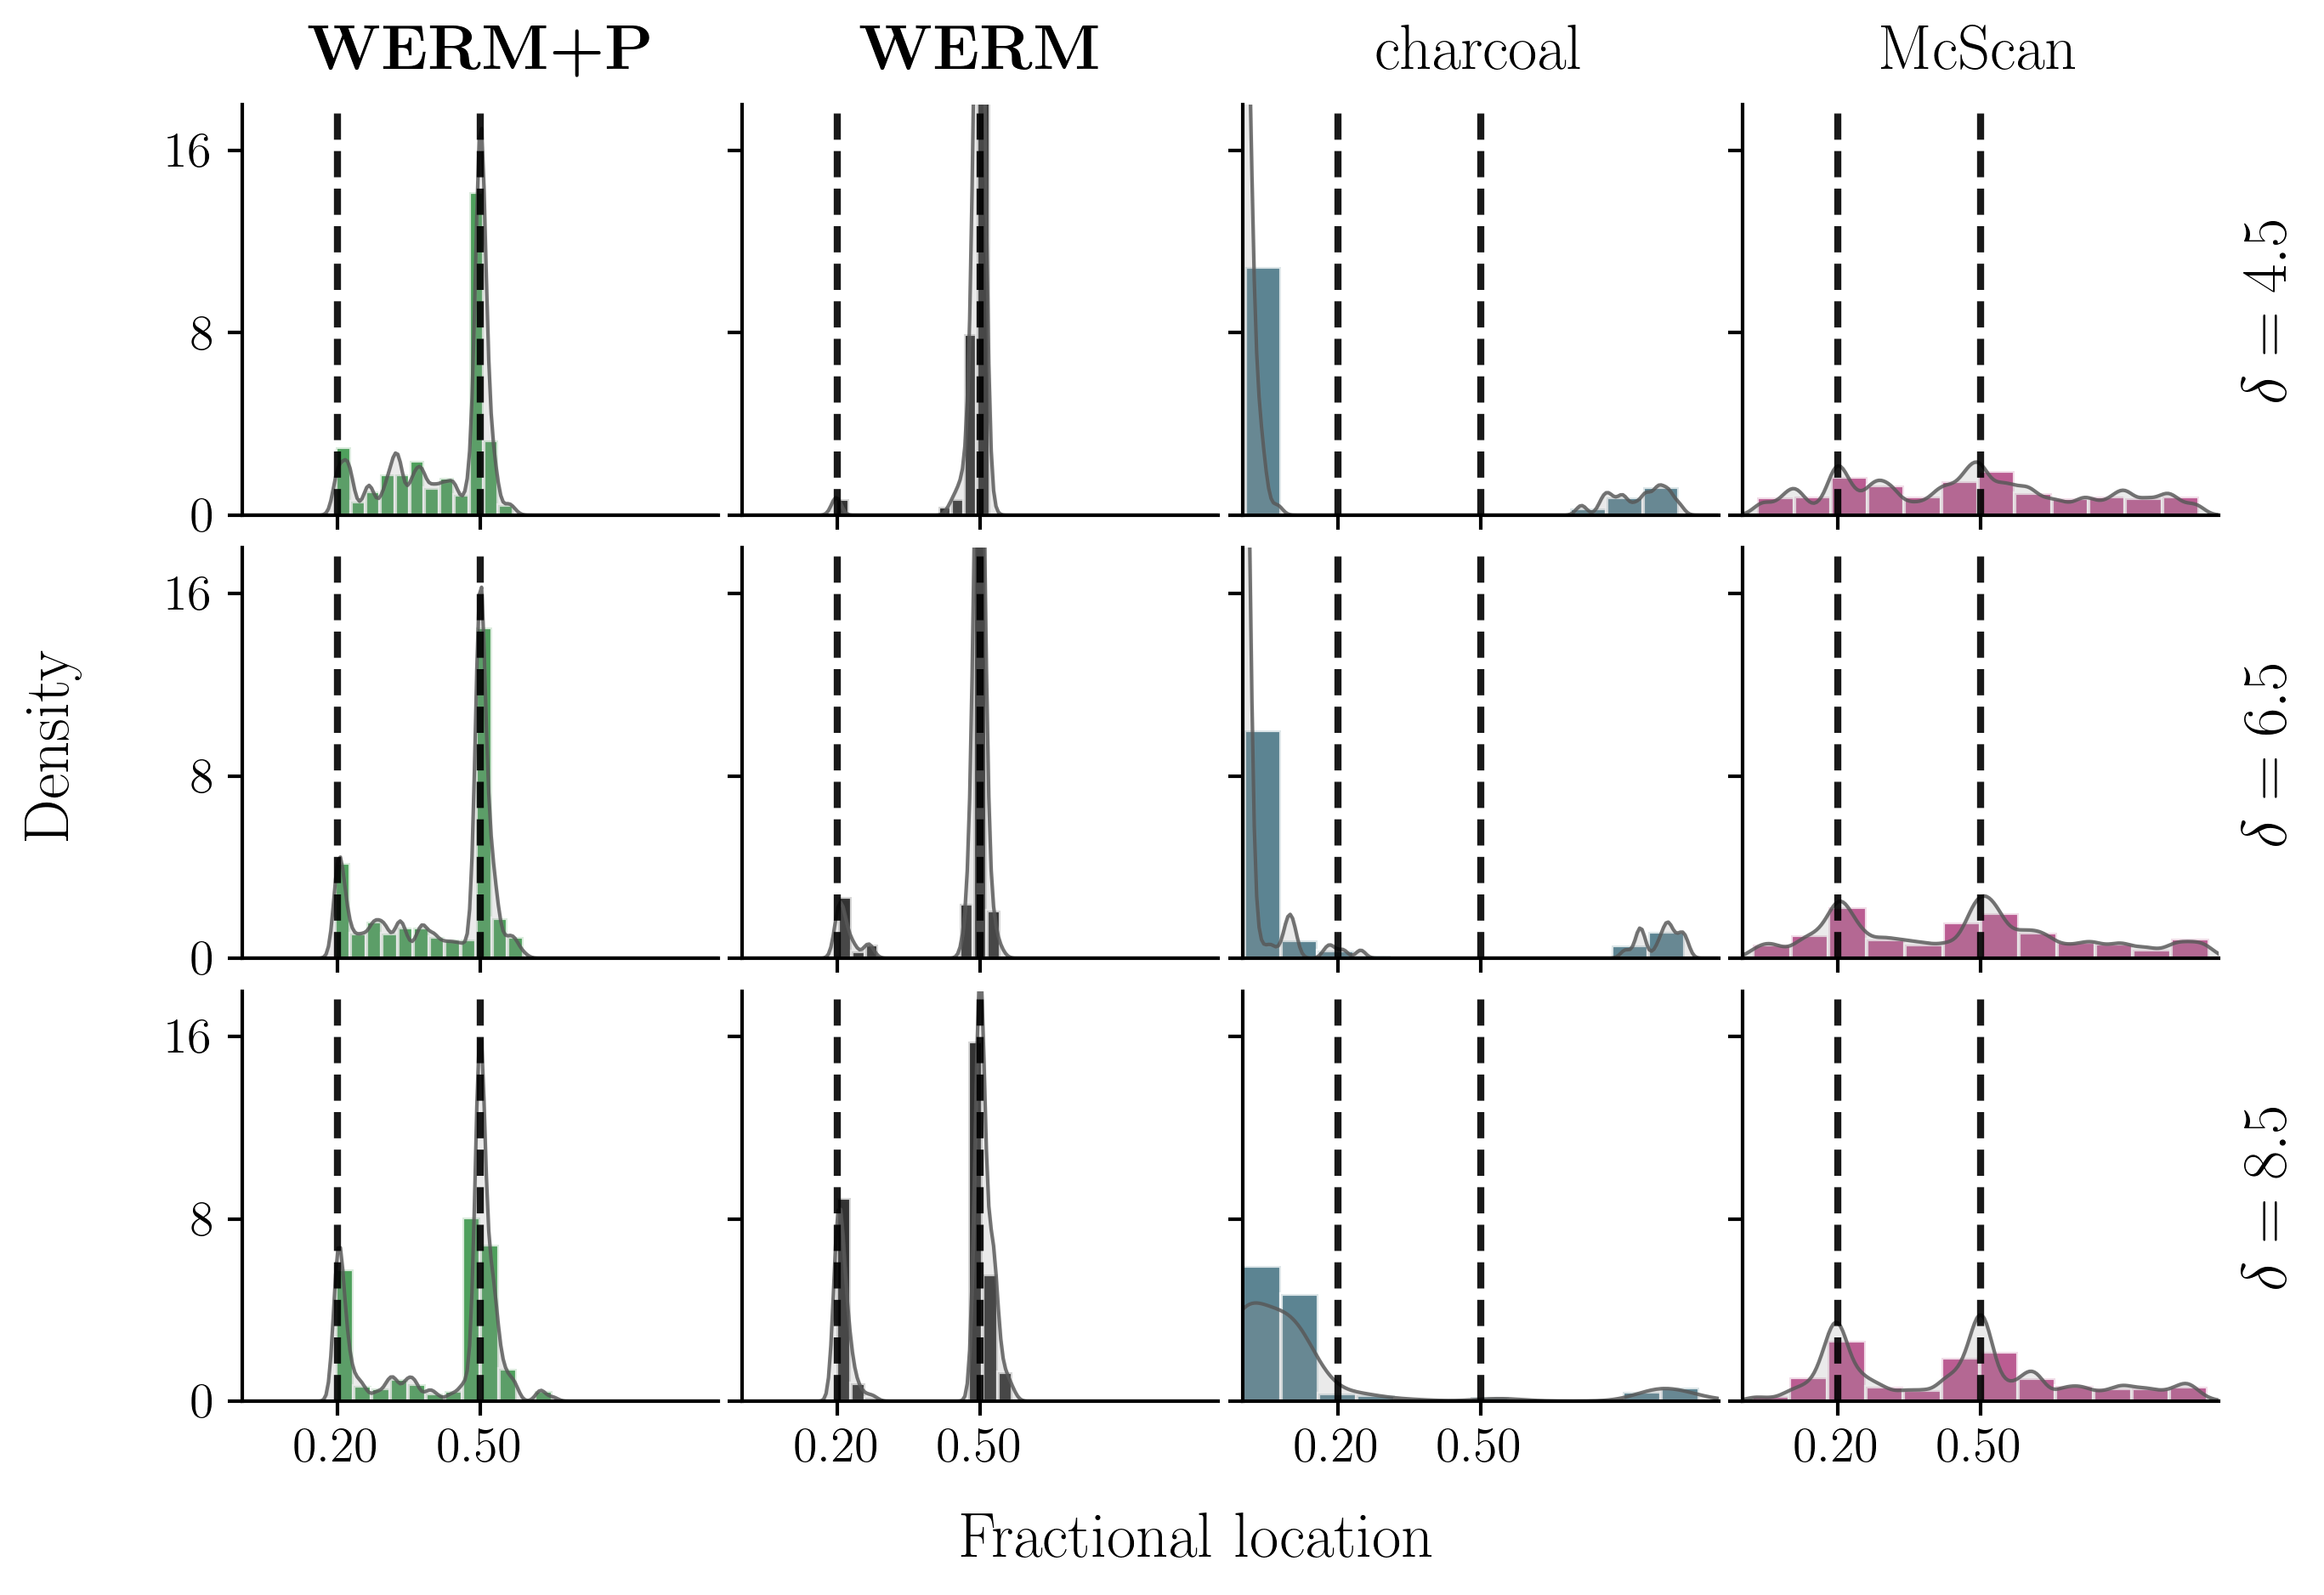

In [1]:
# Run this cell directly in the weighted-erm kernel (Python + R competitors).
def run_m2_fresh_four_method_comparison():
    import os
    import sys
    import time
    import pickle
    import hashlib
    from pathlib import Path
    from contextlib import redirect_stdout, redirect_stderr
    from io import StringIO
    # Use the R installation paired with the active Python environment.
    paired_r = Path(sys.prefix) / 'lib' / 'R'
    if paired_r.is_dir():
        os.environ['R_HOME'] = str(paired_r)
    import numpy as np
    import jax
    import torch
    import WERM.config as config
    import WERM.comparison as competitors
    from WERM.signal_priors import SparseDiffSignal
    from WERM.model import q_linear_model
    from WERM.experiment_utils import trial_rng, data_hash, evaluate_changepoints, weighted_erm_joint_cv
    from WERM.estimators import weighted_erm
    from WERM.gof import manuscript_log_binomial_k_penalty
    from joblib import Parallel, delayed, parallel_config
    from joblib.externals.loky.process_executor import TerminatedWorkerError

    jax.config.update('jax_enable_x64', True)
    gamma = 6.0
    reference_path = Path('results/M2_upsample_final_alpha03_seed42_100trials.pkl')
    reference_bytes = reference_path.read_bytes()
    reference = pickle.loads(reference_bytes)
    params = {key: reference['params'][key] for key in (
        'p', 'L', 'num_trials', 'delta_list', 'fractional_chgpt_locations',
        'fixed_noise_scale', 'random_seed')}
    p, upper_L, trials = int(params['p']), int(params['L']), int(params['num_trials'])
    deltas = np.asarray(params['delta_list'])
    fractions = np.asarray(params['fractional_chgpt_locations'])
    noise_scale = float(params['fixed_noise_scale'])
    assert (p, upper_L, trials) == (200, 4, 100)
    assert np.array_equal(deltas, np.arange(0.5, 16.0, 1.0))
    curve_indices = list(range(len(deltas)))[1:-2:2]
    histogram_indices = list(range(len(deltas)))[4:9:2]
    setting_indices = sorted(set(curve_indices) | set(histogram_indices))
    # The canonical charcoal curve additionally shows delta=2.5. Run charcoal
    # there as well, without adding unplotted WERM or McScan experiments.
    charcoal_indices = [i for i in list(range(len(deltas)))[1:-2] if deltas[i] <= 9.0]
    all_indices = sorted(set(setting_indices) | set(charcoal_indices))
    methods = ('McScan', 'charcoal', 'WERM', 'WERM+P')
    params.update(methods_evaluated=[dict(name=method) for method in methods],
                  num_folds_unpenalized=(10,), charcoal_threshold=float(competitors.CHARCOAL_THRESHOLD),
                  charcoal_seed=int(competitors.CHARCOAL_SEED), charcoal_max_delta=9.0)
    reference_rows = {(int(i), int(j)): row for i, j, row in reference['results']['trial_records']}
    tasks = [(i, j) for i in all_indices for j in range(trials)]
    root = Path('results/M2_upsample_final_WERM_plus_P_gamma6_fresh')
    root.mkdir(parents=True, exist_ok=True)
    signature = dict(schema=1, experiment='fresh-four-method-gamma6', gamma=gamma,
        reference_sha256=hashlib.sha256(reference_bytes).hexdigest(),
        methods=methods, setting_indices=tuple(setting_indices), charcoal_indices=tuple(charcoal_indices),
        trials=trials, marginal_seed=0, r_seed=42, folds=10,
        charcoal_threshold=float(competitors.CHARCOAL_THRESHOLD),
        charcoal_seed=int(competitors.CHARCOAL_SEED), charcoal_max_delta=9.0,
        numpy_version=np.__version__, jax_version=jax.__version__)
    signature['source_sha256'] = {
        name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
        for name in ('WERM/signal_priors.py', 'WERM/model.py', 'WERM/config.py',
                     'WERM/comparison.py', 'WERM/experiment_utils.py',
                     'WERM/estimators.py', 'WERM/proximal.py', 'WERM/gof.py')}

    def save_atomic(path, value):
        tmp = path.with_name(path.name + f'.tmp-{os.getpid()}')
        with tmp.open('wb') as handle:
            pickle.dump(value, handle, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, path)

    def load_checkpoint(i, j):
        path = root / f'setting_{i:02d}_trial_{j:03d}.pkl'
        if path.exists():
            with path.open('rb') as handle:
                payload = pickle.load(handle)
            row = payload['row']
            if (payload.get('signature') == signature and (row['setting'], row['trial']) == (i, j)
                    and row['data_hash'] == reference_rows[i, j]['data_hash']):
                return row
        return None

    def trial(i, j):
        cached = load_checkpoint(i, j)
        if cached is not None:
            return cached
        delta = float(deltas[i]); n = int(delta * p)
        rng = trial_rng('M2c-alpha-0.3', i, j)
        B = SparseDiffSignal(8, np.sqrt(400 * delta), 0.3, upper_L).sample(p, rng=rng)
        X = rng.normal(0, np.sqrt(1 / n), (n, p))
        noise = rng.normal(0, 1, size=n) * noise_scale
        X = X @ np.linalg.cholesky(np.eye(p)).T
        X_scaled = X * np.sqrt(n)
        truth = (n * fractions).astype(int)
        theta = X_scaled @ (B / np.sqrt(n))
        y = np.asarray(jax.vmap(q_linear_model, in_axes=(0, 0, 0))(
            theta, config.η_to_ψ(truth, n), noise))
        fingerprint = data_hash(X, y)
        assert fingerprint == reference_rows[i, j]['data_hash'], (i, j, 'data hash mismatch')
        estimates, diagnostics = {}, {}

        def record(name, cp, elapsed):
            estimates[name] = dict(runtime=float(elapsed), **evaluate_changepoints(cp, truth, n))

        with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
            if i in setting_indices:
                competitors.ro.r['set.seed'](42)
                start = time.perf_counter()
                cp = competitors.run_mcscan(X_scaled, y.flatten(), num_chgpts=None, method='auto')
                record('McScan', cp, time.perf_counter() - start)
            if delta <= 9.0:
                start = time.perf_counter()
                try:
                    cp = competitors.run_charcoal(X_scaled, y)
                except competitors.rpy2.rinterface_lib.embedded.RRuntimeError as exc:
                    diagnostics['charcoal_R_error'] = str(exc)
                    cp = np.array([], dtype=int)
                record('charcoal', cp, time.perf_counter() - start)
            else:
                record('charcoal', None, np.nan)
                diagnostics['charcoal'] = 'not applicable above delta=9'

        row = dict(setting=i, trial=j, n=n, true_cp=truth, data_hash=fingerprint,
                   estimates=estimates, diagnostics=diagnostics)
        if i in setting_indices:
            # Cache the same fixed-count marginal weights for BOTH methods.
            # The interpolation is a function of sample size/count/spacing only.
            # Seed its random optimizer restarts independently of the data RNG.
            original_marginals = config.extrapolated_marginals
            marginal_cache = {}
            def shared_marginals(Lmin, Lmax, Delta_small, n_small=50, n_large=1000,
                                 p_l=None, verbose='summary'):
                prior = None if p_l is None else tuple(np.asarray(p_l).tolist())
                key = (int(Lmin), int(Lmax), int(Delta_small), int(n_small), int(n_large), prior)
                if key not in marginal_cache:
                    numpy_state, torch_state = np.random.get_state(), torch.random.get_rng_state()
                    try:
                        np.random.seed(0); torch.manual_seed(0)
                        marginal_cache[key] = original_marginals(
                            Lmin, Lmax, Delta_small, n_small=n_small, n_large=n_large,
                            p_l=p_l, verbose=False)
                    finally:
                        np.random.set_state(numpy_state); torch.random.set_rng_state(torch_state)
                return marginal_cache[key].copy()

            loss = lambda u, v: (np.asarray(u) - np.asarray(v)) ** 2
            scorer = lambda u, v: np.abs(np.asarray(u) - np.asarray(v))
            config.extrapolated_marginals = shared_marginals
            try:
                with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
                    # Prepare full-data and 10-fold training-size weights once.
                    # Both WERM timings exclude this common preparation cost.
                    prep_start = time.perf_counter()
                    sample_sizes = {n} | {n - len(np.arange(f, n, 10)) for f in range(10)}
                    for length in sorted(sample_sizes):
                        separation = max(int(np.ceil(length / 50)), int(length / 40), 1)
                        for k in range(1, upper_L + 1):
                            shared_marginals(k, k, int(separation * 50 / length),
                                             n_small=50, n_large=length, verbose=False)
                    row['marginal_preparation_seconds'] = time.perf_counter() - prep_start

                    start = time.perf_counter()
                    (cv_k, _), cv_cp, cv_diagnostics = weighted_erm_joint_cv(
                        X=X, y=y, M=loss, M_scorer=scorer, Lmax=upper_L,
                        delta_fraction=1/40, l1_constants=(0.0,), num_folds=10,
                        n_jobs=1, standardize_y=False, selection_strategy='exhaustive',
                        penalty_norm='none', coefficient_loss='least_squares',
                        return_diagnostics=True)
                    record('WERM', cv_cp, time.perf_counter() - start)

                    start = time.perf_counter()
                    candidates, raw = {}, []
                    separation = max(int(np.ceil(n / 50)), int(n / 40), 1)
                    for k in range(1, upper_L + 1):
                        cp, objective = weighted_erm(
                            X=X, y=y, M=loss, L=k, Delta_n=separation, gamma=0.0,
                            L_is_upper_bound=False, return_gof=True,
                            coefficient_loss='least_squares', coefficient_penalty='none',
                            coefficient_lambda=0.0)
                        candidates[k] = np.asarray(cp, dtype=int)
                        raw.append(float(objective))
                    penalty = manuscript_log_binomial_k_penalty(n, gamma)
                    objectives = np.asarray(raw) + np.array([penalty(k) for k in range(1, upper_L + 1)])
                    selected_k = 1 + int(np.argmin(objectives))
                    record('WERM+P', candidates[selected_k], time.perf_counter() - start)
                    # Same data, count, weights, solver, and DP search must agree.
                    assert np.array_equal(candidates[int(cv_k)], cv_cp), (i, j, cv_k)
                    row.update(cv_K=int(cv_k), penalty_K=selected_k, raw_by_K=np.asarray(raw),
                               cp_by_K=candidates, cv_diagnostics=cv_diagnostics,
                               cv_fixed_count_match=True, penalty_objectives=objectives)
            finally:
                config.extrapolated_marginals = original_marginals
        save_atomic(root / f'setting_{i:02d}_trial_{j:03d}.pkl', dict(signature=signature, row=row))
        return row

    completed = {}
    for i, j in tasks:
        cached = load_checkpoint(i, j)
        if cached is not None:
            completed[i, j] = cached
    jobs = max(1, int(os.environ.get('M2_FRESH_JOBS', '24')))
    print(f'Fresh four-method comparison: {len(completed)}/{len(tasks)} checkpoints available', flush=True)
    crashes = 0
    while len(completed) < len(tasks):
        pending = [(i, j) for i, j in tasks if (i, j) not in completed]
        try:
            with parallel_config(backend='loky', inner_max_num_threads=1):
                stream = Parallel(n_jobs=min(jobs, len(pending)), batch_size=1,
                                  pre_dispatch=jobs, return_as='generator_unordered')(
                    delayed(trial)(i, j) for i, j in pending)
                for row in stream:
                    completed[row['setting'], row['trial']] = row
                    if len(completed) % 20 == 0 or len(completed) == len(tasks):
                        print(f'Fresh four-method comparison: {len(completed)}/{len(tasks)} trials complete', flush=True)
        except TerminatedWorkerError:
            crashes += 1
            for i, j in pending:
                cached = load_checkpoint(i, j)
                if cached is not None:
                    completed[i, j] = cached
            if crashes > 3:
                raise
            jobs = max(1, jobs // 2)
            print(f'Retrying after worker exit; parallelism now {jobs}', flush=True)
        print(f'Fresh four-method comparison: {len(completed)}/{len(tasks)} trials complete', flush=True)
    rows = [completed[key] for key in tasks]
    metrics = {name: {metric: np.full((len(deltas), trials), np.nan)
                      for metric in ('haus', 'size', 'runtime')} for name in methods}
    for row in rows:
        for method, result in row['estimates'].items():
            for metric in ('haus', 'size', 'runtime'):
                metrics[method][metric][row['setting'], row['trial']] = result[metric]
    paired = [row for row in rows if row['setting'] in setting_indices]
    same_count = [row for row in paired if row['cv_K'] == row['penalty_K']]
    exact = sum(np.array_equal(row['estimates']['WERM']['raw_cp'], row['estimates']['WERM+P']['raw_cp'])
                for row in same_count)
    assert exact == len(same_count)
    comparison = dict(signature=signature, params=params, gamma=gamma, methods=methods,
        trial_records=rows, metrics=metrics, setting_indices=setting_indices,
        charcoal_indices=charcoal_indices, curve_indices=curve_indices,
        histogram_indices=histogram_indices,
        conditional_location_audit=dict(same_count=len(same_count), identical_locations=exact),
        charcoal_R_errors=sum('charcoal_R_error' in row['diagnostics'] for row in rows))
    save_atomic(root / 'comparison.pkl', comparison)
    print(f'Completed {len(paired)} fresh four-method trials plus 100 charcoal-only trials at delta=2.5.')
    print(f'Same-count location agreement: {exact}/{len(same_count)}; charcoal R errors: {comparison["charcoal_R_errors"]}')
    print(f'Saved {root / "comparison.pkl"}', flush=True)
    return comparison


def plot_m2_fresh_canonical(comparison):
    # Canonical plotting functions below are copied from cell 6. Their figure
    # sizes, axes, percentile error bars, spacing, KDE, and delta slices are retained.
    from pathlib import Path
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.neighbors import KernelDensity
    from sklearn.model_selection import GridSearchCV
    import pickle

    params = comparison['params']
    p, L = int(params['p']), int(params['L'])
    δ_list = np.asarray(params['delta_list'])
    fractional_chgpt_locations = np.asarray(params['fractional_chgpt_locations'])
    methods_to_evaluate = [
        dict(name='McScan', label='McScan', color='#AA3377', marker='o', linestyle='--'),
        dict(name='charcoal', label='charcoal', color='#336677', marker='v', linestyle='-.'),
        dict(name='WERM', label=r'\textbf{WERM}', color='black', marker='D', linestyle='-'),
        dict(name='WERM+P', label=r'\textbf{WERM+P}', color='#228833', marker='P', linestyle='-'),
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]
    PAL = [method['color'] for method in methods_to_evaluate]
    kde_style = dict(color='#555555', linestyle='-', linewidth=1.0, alpha=0.8,
                     fill_color='#999999', fill_alpha=0.2)
    results = {}
    for method in method_names_list:
        for metric in ('haus', 'size', 'runtime'):
            results[f'{metric}_{method}'] = comparison['metrics'][method][metric]
        results[f'chgpts_{method}'] = [
            (row['setting'], row['estimates'][method]['raw_cp'])
            for row in comparison['trial_records']
            if method in row['estimates'] and row['estimates'][method]['raw_cp'] is not None]

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1)
        p25 = np.nanpercentile(data, 25, axis=1)
        p75 = np.nanpercentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication(plot_type='all'):
        """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
        if plot_type == 'all':
            fig, axs = plt.subplots(1, 3, figsize=(20, 6))
            fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
        else:
            fig, axs = plt.subplots(1, 1, figsize=(5.0, 4.0))
    
        # Use method_names_list from the loaded/generated params
        methods = method_names_list
        colors = PAL[:len(methods)] # Use as many colors as methods
    
        # Define markers and linestyles to match the number of methods
        markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
        linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
        labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
        # labels = ['\\textbf{McScan}', '\\textbf{MOSEG}', '\\textbf{WERM}']
        # labels = ['McScan', 'MOSEG', 'WERM']
    
        # Hausdorff Distance Plot
        if plot_type == 'all' or plot_type == 'location':
            if plot_type == 'all': ax = axs[0]
            elif plot_type == 'location': ax = axs

            for i, method_name in enumerate(methods):
                data = results[f'haus_{method_name}']
                if method_name == 'charcoal':
                    skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                else:
                    skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                end_idx = -2
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                # Set all infs to NaN for plotting
                data_effective = np.where(np.isinf(data_effective), np.nan, data_effective)
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)

                # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
                means = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, errors)
            
                ax.errorbar(delta_effective, means, yerr=errors,
                            label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                            color=colors[i], capsize=4, capthick=2, markersize=8,
                            linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                            alpha=0.8)
        
            ax.set_ylim((0, 0.55))
            ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
            ax.set_ylabel(r'Hausdorff dist. / $n$', fontsize=18)
            if plot_type == 'all':
                ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        
            # Cleaner x-axis with fewer ticks
            ax.set_xticks(delta_effective[::2])  # Show every other tick
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
    
        # Changepoint Set Size Plot
        if plot_type == 'all' or plot_type == 'size':
            if plot_type == 'all': ax = axs[1]
            elif plot_type == 'size': ax = axs

            for i, method_name in enumerate(methods):
                if method_name == 'charcoal':
                    skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                else:
                    skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                end_idx = -2
                data = results[f'size_{method_name}']
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)

                # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
                means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)

                ax.errorbar(delta_effective, means, yerr=errors,
                            label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                            color=colors[i], capsize=4, capthick=2, markersize=8,
                            linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                            alpha=0.8)
        
            ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-',
                       linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
            ax.set_ylim((0, L + 1))
            ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
            ax.set_ylabel(r'No. change points', fontsize=18)
            if plot_type == 'all':
                ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        
            ax.set_xticks(delta_effective[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
    
        # Runtime Plot
        if plot_type == 'all' or plot_type == 'runtime':
            if plot_type == 'all': ax = axs[2]
            elif plot_type == 'runtime': ax = axs
            for i, method_name in enumerate(methods):
                if method_name == 'charcoal':
                    skip_factor = 1 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                else:
                    skip_factor = 2 # Adjust this factor to skip more or fewer points on the x-axis for error bars
                    start_idx = 1 # Start from index 1 to avoid the very first point if needed
                end_idx = -2
                data = results[f'runtime_{method_name}']
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)

                # If method is 'charcoal', set all means and errors to NaN (don't plot) for all deltas greater than 9.5
                means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)
            
                ax.errorbar(delta_effective, means, yerr=errors,
                            label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'],
                            color=colors[i], capsize=4, capthick=2, markersize=8,
                            linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
        
            ax.set_ylim(bottom=0)
            ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
            ax.set_ylabel(r'Runtime (s)', fontsize=18)
            if plot_type == 'all':
                ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        
            ax.set_xticks(delta_effective[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
    
        if plot_type == 'all':
            # Single legend for all subplots
            handles, labels_leg = axs[1].get_legend_handles_labels()
            if plot_type != 'location':
                fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                        ncol=len(methods)+1, fontsize=14, frameon=True,
                        edgecolor='black', framealpha=0.95)
            plt.tight_layout(rect=[0, 0.08, 1, 0.95])
        else:
            if plot_type != 'location' and plot_type != 'size':
                ax.legend(loc='best', prop={'size': 14}, fancybox = True, framealpha = 0.4)
            fig.tight_layout()
    
        # plt.show() # Removed plt.show() as per the original structure that saves then shows
        return fig, axs

    def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
        """
        Publication-ready changepoint location histograms with tight layout
        """
    
        # 1. Setup Data
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
        current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
        current_method_names = [method['name'] for method in current_methods]

        # Reverse order as per original request
        method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)}
        method_colors_map = {k: method_colors_map[k] for k in reversed(method_colors_map)}
        current_methods = list(reversed(current_methods))
        current_method_names = list(reversed(current_method_names))

        selected_deltas_idx = list(range(len(δ_list)))[4:9:2]
        selected_deltas = δ_list[4:9:2]
    
        num_rows = len(selected_deltas)
        num_cols = len(current_methods)

        # 2. Setup Figure - TIGHTER DIMENSIONS
        # Using a roughly 3:2.5 ratio per subplot, scaled for standard latex textwidth
        # A width of 14-16 inches usually scales down perfectly to a 7 inch page width
        fig, axes = plt.subplots(num_rows, num_cols,
                                 figsize=(2.5 * num_cols, 2.2 * num_rows), 
                                 sharex=True, sharey=True,
                                 gridspec_kw={'wspace': 0.05, 'hspace': 0.08}) # <--- KEY FOR TIGHTNESS
    
        # Handle single subplot cases to ensure axes is always 2D array
        if num_rows == 1 and num_cols == 1:
            axes = np.array([[axes]])
        elif num_cols == 1:
            axes = axes.reshape(-1, 1)
        elif num_rows == 1:
            axes = axes.reshape(1, -1)
    
        fig.patch.set_facecolor('white')

        # 3. Plotting Loop
        for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
            n = int(delta * p)
        
            for col, method_name in enumerate(current_method_names):
                ax = axes[row, col]
                ax.set_facecolor('white')
            
                # --- Data Collection (Same as original) ---
                all_chgpts = []
                chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
                for res_delta_idx, chgpts_list in chgpts_data_for_method:
                    if res_delta_idx == delta_idx:
                        for chgpts in chgpts_list:
                            if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                                chgpts_array = np.array(chgpts)
                                valid_chgpts = chgpts_array[chgpts_array != -1]
                                for chgpt in valid_chgpts:
                                    all_chgpts.append(chgpt / n)
                            elif np.isscalar(chgpts) and chgpts != -1:
                                all_chgpts.append(chgpts / n)
            
                # --- Plotting ---
                if len(all_chgpts) > 0:
                    # Histogram
                    counts, bins, patches = ax.hist(all_chgpts, bins=12, alpha=0.8,
                                                    color=method_colors_map[method_name],
                                                    density=True, edgecolor='white',
                                                    linewidth=1.0) # Thinner line for tighter look
                
                    # KDE (GridSearch Logic)
                    if len(all_chgpts) > 6:
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                    
                        x_range = np.linspace(0, 1, 200)
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                    
                        ax.plot(x_range, kde_values, 
                                color=kde_style['color'], 
                                linewidth=kde_style['linewidth'],
                                linestyle=kde_style['linestyle'],
                                alpha=kde_style['alpha'], zorder=2)
                    
                        ax.fill_between(x_range, kde_values, 
                                        color=kde_style['fill_color'], 
                                        alpha=kde_style['fill_alpha'],
                                        zorder=1)
                else:
                    ax.text(0.5, 0.5, r'\textit{N/A}',
                            transform=ax.transAxes, ha='center', va='center',
                            fontsize=12, alpha=0.7, style='italic')
            
                # True Changepoints
                for i, true_chgpt in enumerate(fractional_chgpt_locations):
                    ax.axvline(x=true_chgpt, color='black', linestyle='--', 
                               linewidth=2, alpha=0.9, zorder=10,
                               label=r'\textbf{True changepoints}' if i == 0 else "")

                # --- Formatting & Ticks ---
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 18) # Enforce uniform height
            
                # Clean spines
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.spines['left'].set_linewidth(1.0)
                ax.spines['bottom'].set_linewidth(1.0)
            
                # Custom ticks - apply to ALL, but sharex hides labels automatically
                ax.set_xticks(np.array([*fractional_chgpt_locations]))
                ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=14)
                ax.set_yticks([0, 8, 16]) # Minimal Y-ticks
            
                # Tick parameters
                # 'labelleft' and 'labelbottom' control visibility explicitly if sharex/y fails
                ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)

                # 4. Labels and Titles (Specific Locations Only)
            
                # Column Titles (Method Names) - Only Top Row
                if row == 0:
                    ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=10)
            
                # Row Labels (Delta) - Right side of Last Column
                if col == num_cols - 1:
                    # Use ax.text roughly in the middle right
                    ax.text(1.05, 0.5, f'$\delta = {delta}$', transform=ax.transAxes,
                            rotation=90, verticalalignment='center', horizontalalignment='left',
                            fontsize=18, fontweight='bold')

                # X-Axis Label - Bottom Row, Centered on Figure not Subplot
                # We skip per-subplot labels to save space
    
        # Global Labels (cleaner than per-subplot)
        fig.text(0.5, 0.01, 'Fractional location', 
                 ha='center', va='bottom', fontsize=18)
        fig.text(0.04, 0.5, r'Density', 
                 va='center', rotation='vertical', fontsize=18)

        # 5. Legend
        # Place one legend for the whole figure, or inside the first visible plot
        # Here we put it in the first plot, but make it compact
        first_ax = axes[0, 0]
        handles, labels = first_ax.get_legend_handles_labels()
        # if handles:
        #     # Create a legend that floats slightly inside the plot
        #     legend = first_ax.legend(loc='upper right', fontsize=18, frameon=True,
        #                              edgecolor='white', framealpha=0.8, handlelength=1.5)
        #     legend.set_zorder(20)

        # Final Tight Layout to handle the global labels
        # rect tuple is (left, bottom, right, top)
        plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96]) 
    
        return fig, axes

    figures = []
    figure_root = Path('figures/M2_upsample_final_WERM_plus_P_gamma6_fresh')
    figure_root.mkdir(parents=True, exist_ok=True)
    with plt.rc_context():
        plt.rcParams.update({
            'pgf.texsystem': 'pdflatex',
            'pgf.preamble': r'''
                \usepackage{amsmath}
                \usepackage{amsfonts}
                \usepackage{amssymb}
                \usepackage{siunitx}
            ''',
            'font.size': 14,
            'font.family': 'serif',
            'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
            'text.usetex': True,
            'axes.linewidth': 1.5,
            'axes.labelsize': 18,
            'axes.titlesize': 18,
            'xtick.labelsize': 14,
            'ytick.labelsize': 14,
            'legend.fontsize': 14,
            'legend.frameon': True,
            'legend.fancybox': True,
            'legend.edgecolor': 'black',
            'legend.framealpha': 0.95,
            'lines.linewidth': 4.0,
            'lines.markersize': 8,
            'figure.dpi': 72,
            'savefig.dpi': 300,
            'savefig.bbox': 'tight',
            'savefig.pad_inches': 0.1
        })
        for metric in ('location', 'size', 'runtime'):
            fig, _ = plot_with_asymmetric_errors_publication(plot_type=metric)
            for extension in ('png', 'pdf', 'pgf'):
                fig.savefig(figure_root / f'{metric}.{extension}', dpi=300, bbox_inches='tight')
            figures.append((metric, fig))
            plt.show()
        fig, _ = plot_changepoint_histograms_publication(
            results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
        for extension in ('png', 'pdf', 'pgf'):
            fig.savefig(figure_root / f'chgpt_histograms.{extension}', dpi=300, bbox_inches='tight')
        figures.append(('chgpt_histograms', fig))
        plt.show()
    print(f'Saved canonical figures to {figure_root}')
    return figures



m2_fresh_comparison = run_m2_fresh_four_method_comparison()
m2_fresh_figures = plot_m2_fresh_canonical(m2_fresh_comparison)


## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/M2/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(.07,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric == ('size' if m3 else 'runtime'):
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/M2')


### Original three-method experiment — Canonical M2 Comparison Experiment plots

Original M2: McScan, charcoal, WERM (unpenalized, 10-fold CV); 100 trials per setting.


M2_original_haus_line


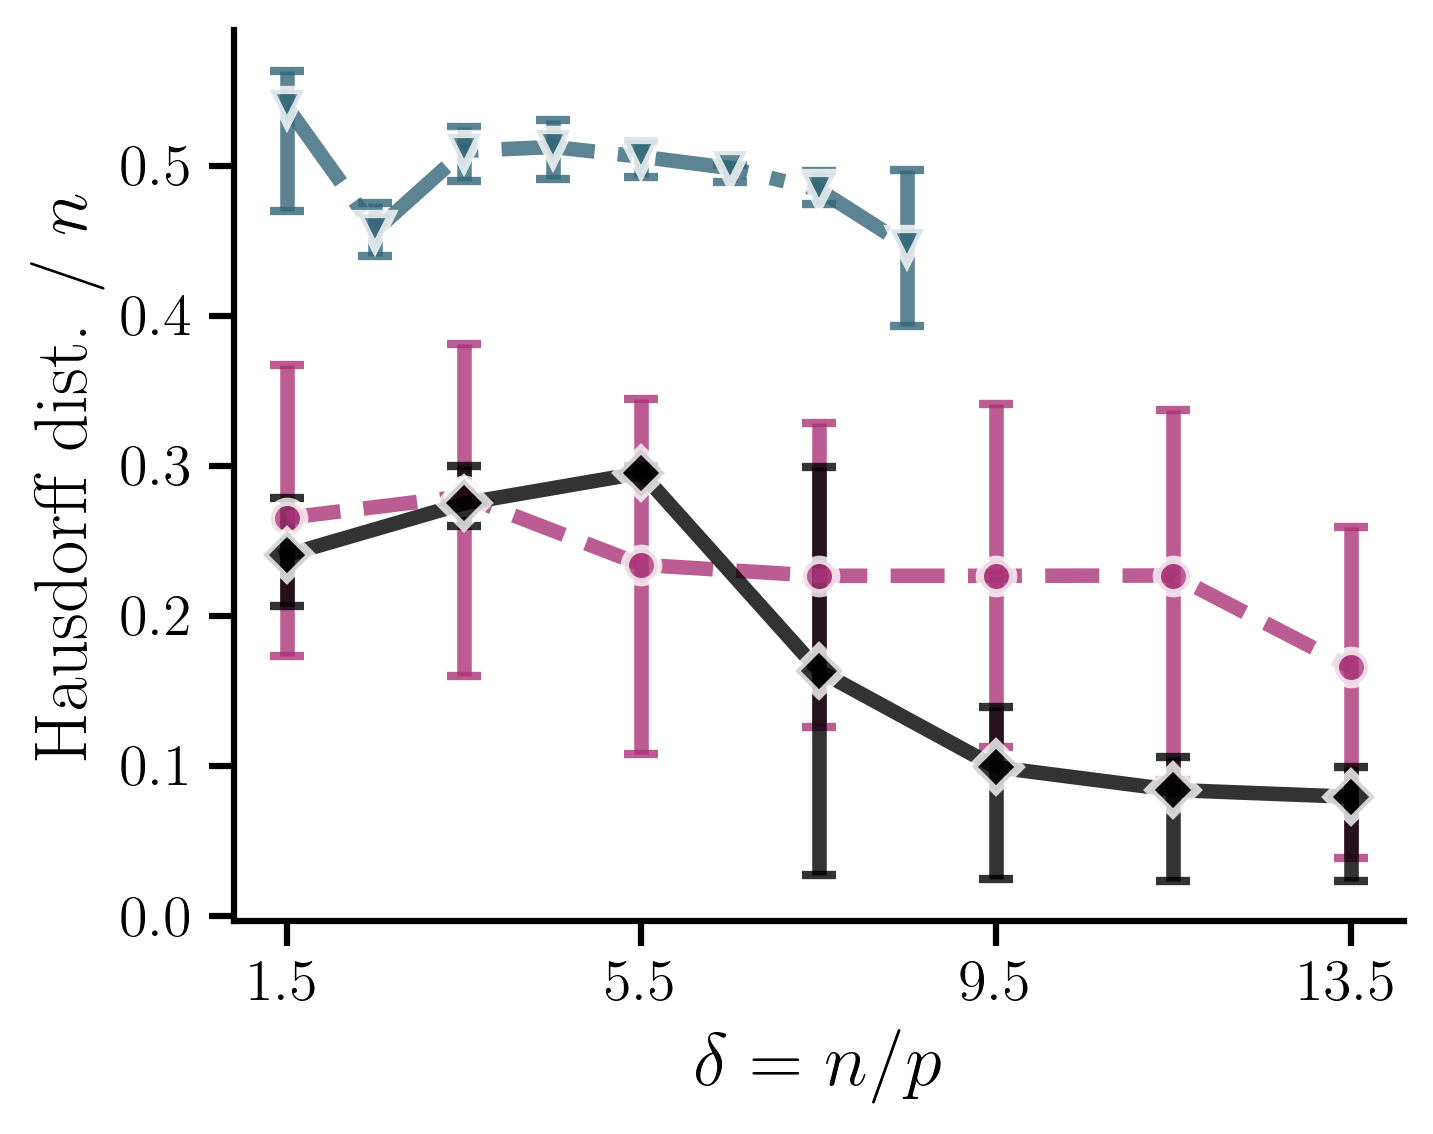

M2_original_haus_box


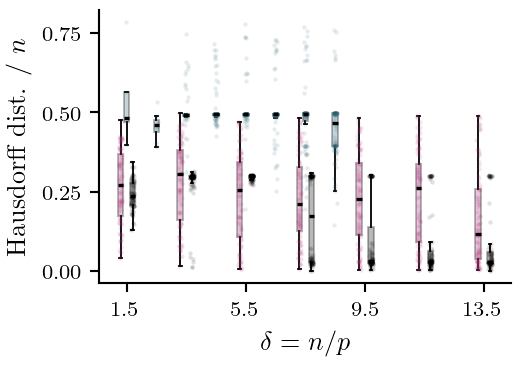

M2_original_size_line


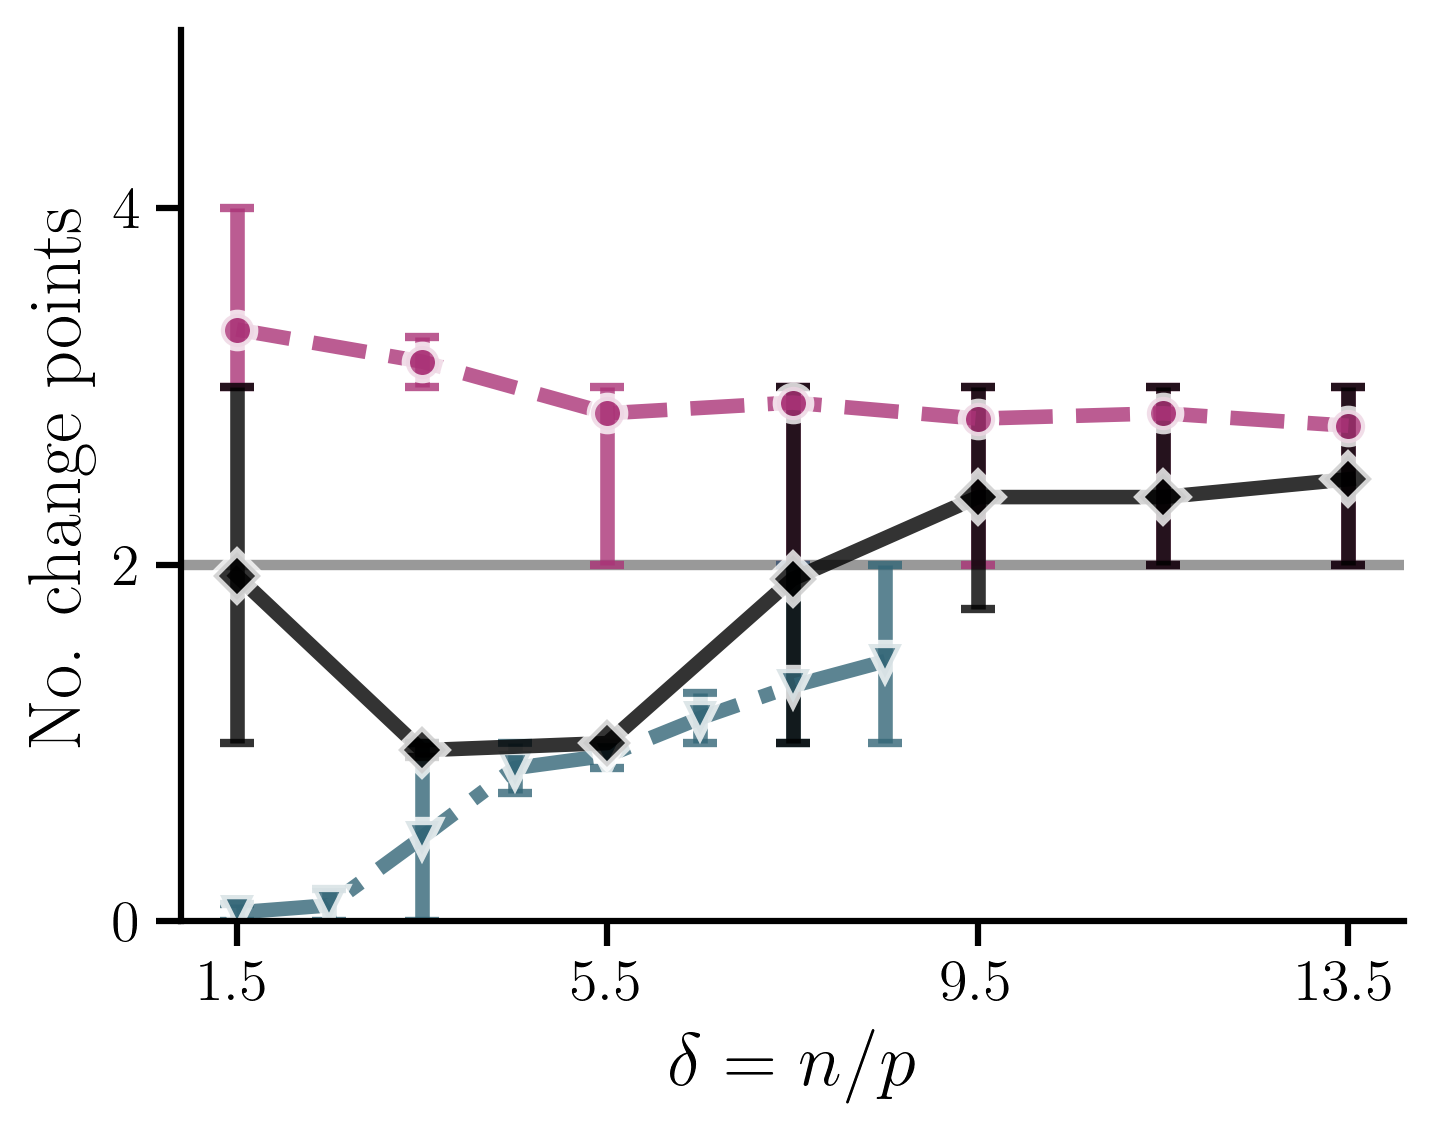

M2_original_size_box


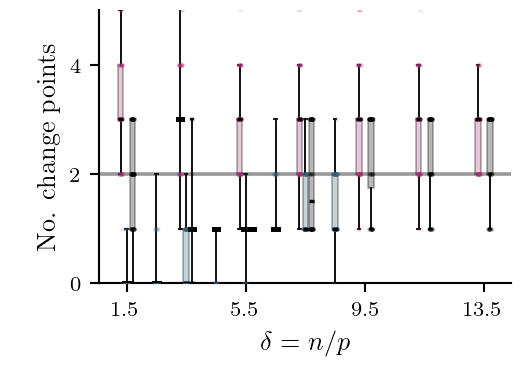

M2_original_runtime_line


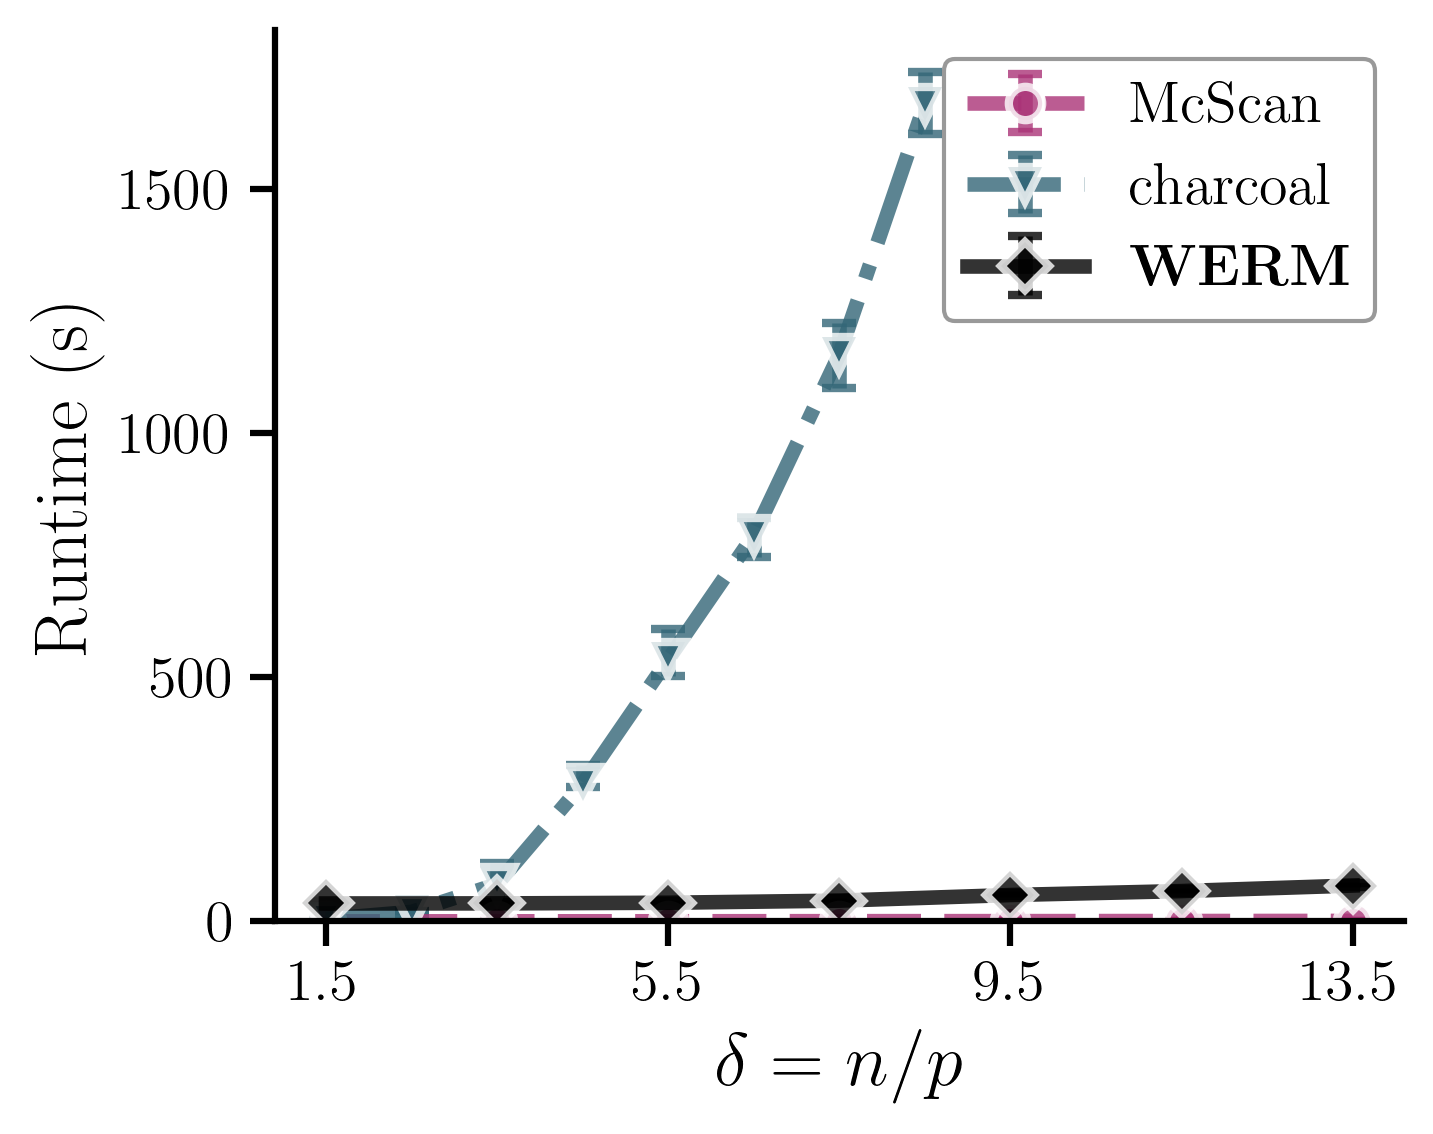

M2_original_runtime_box


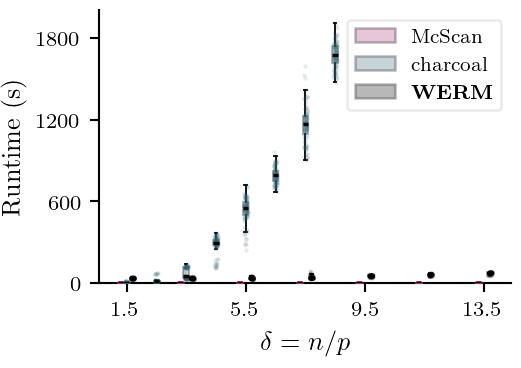

/tmp/ipykernel_3311065/2723109197.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


M2_original_hist: maximum density 29.33; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


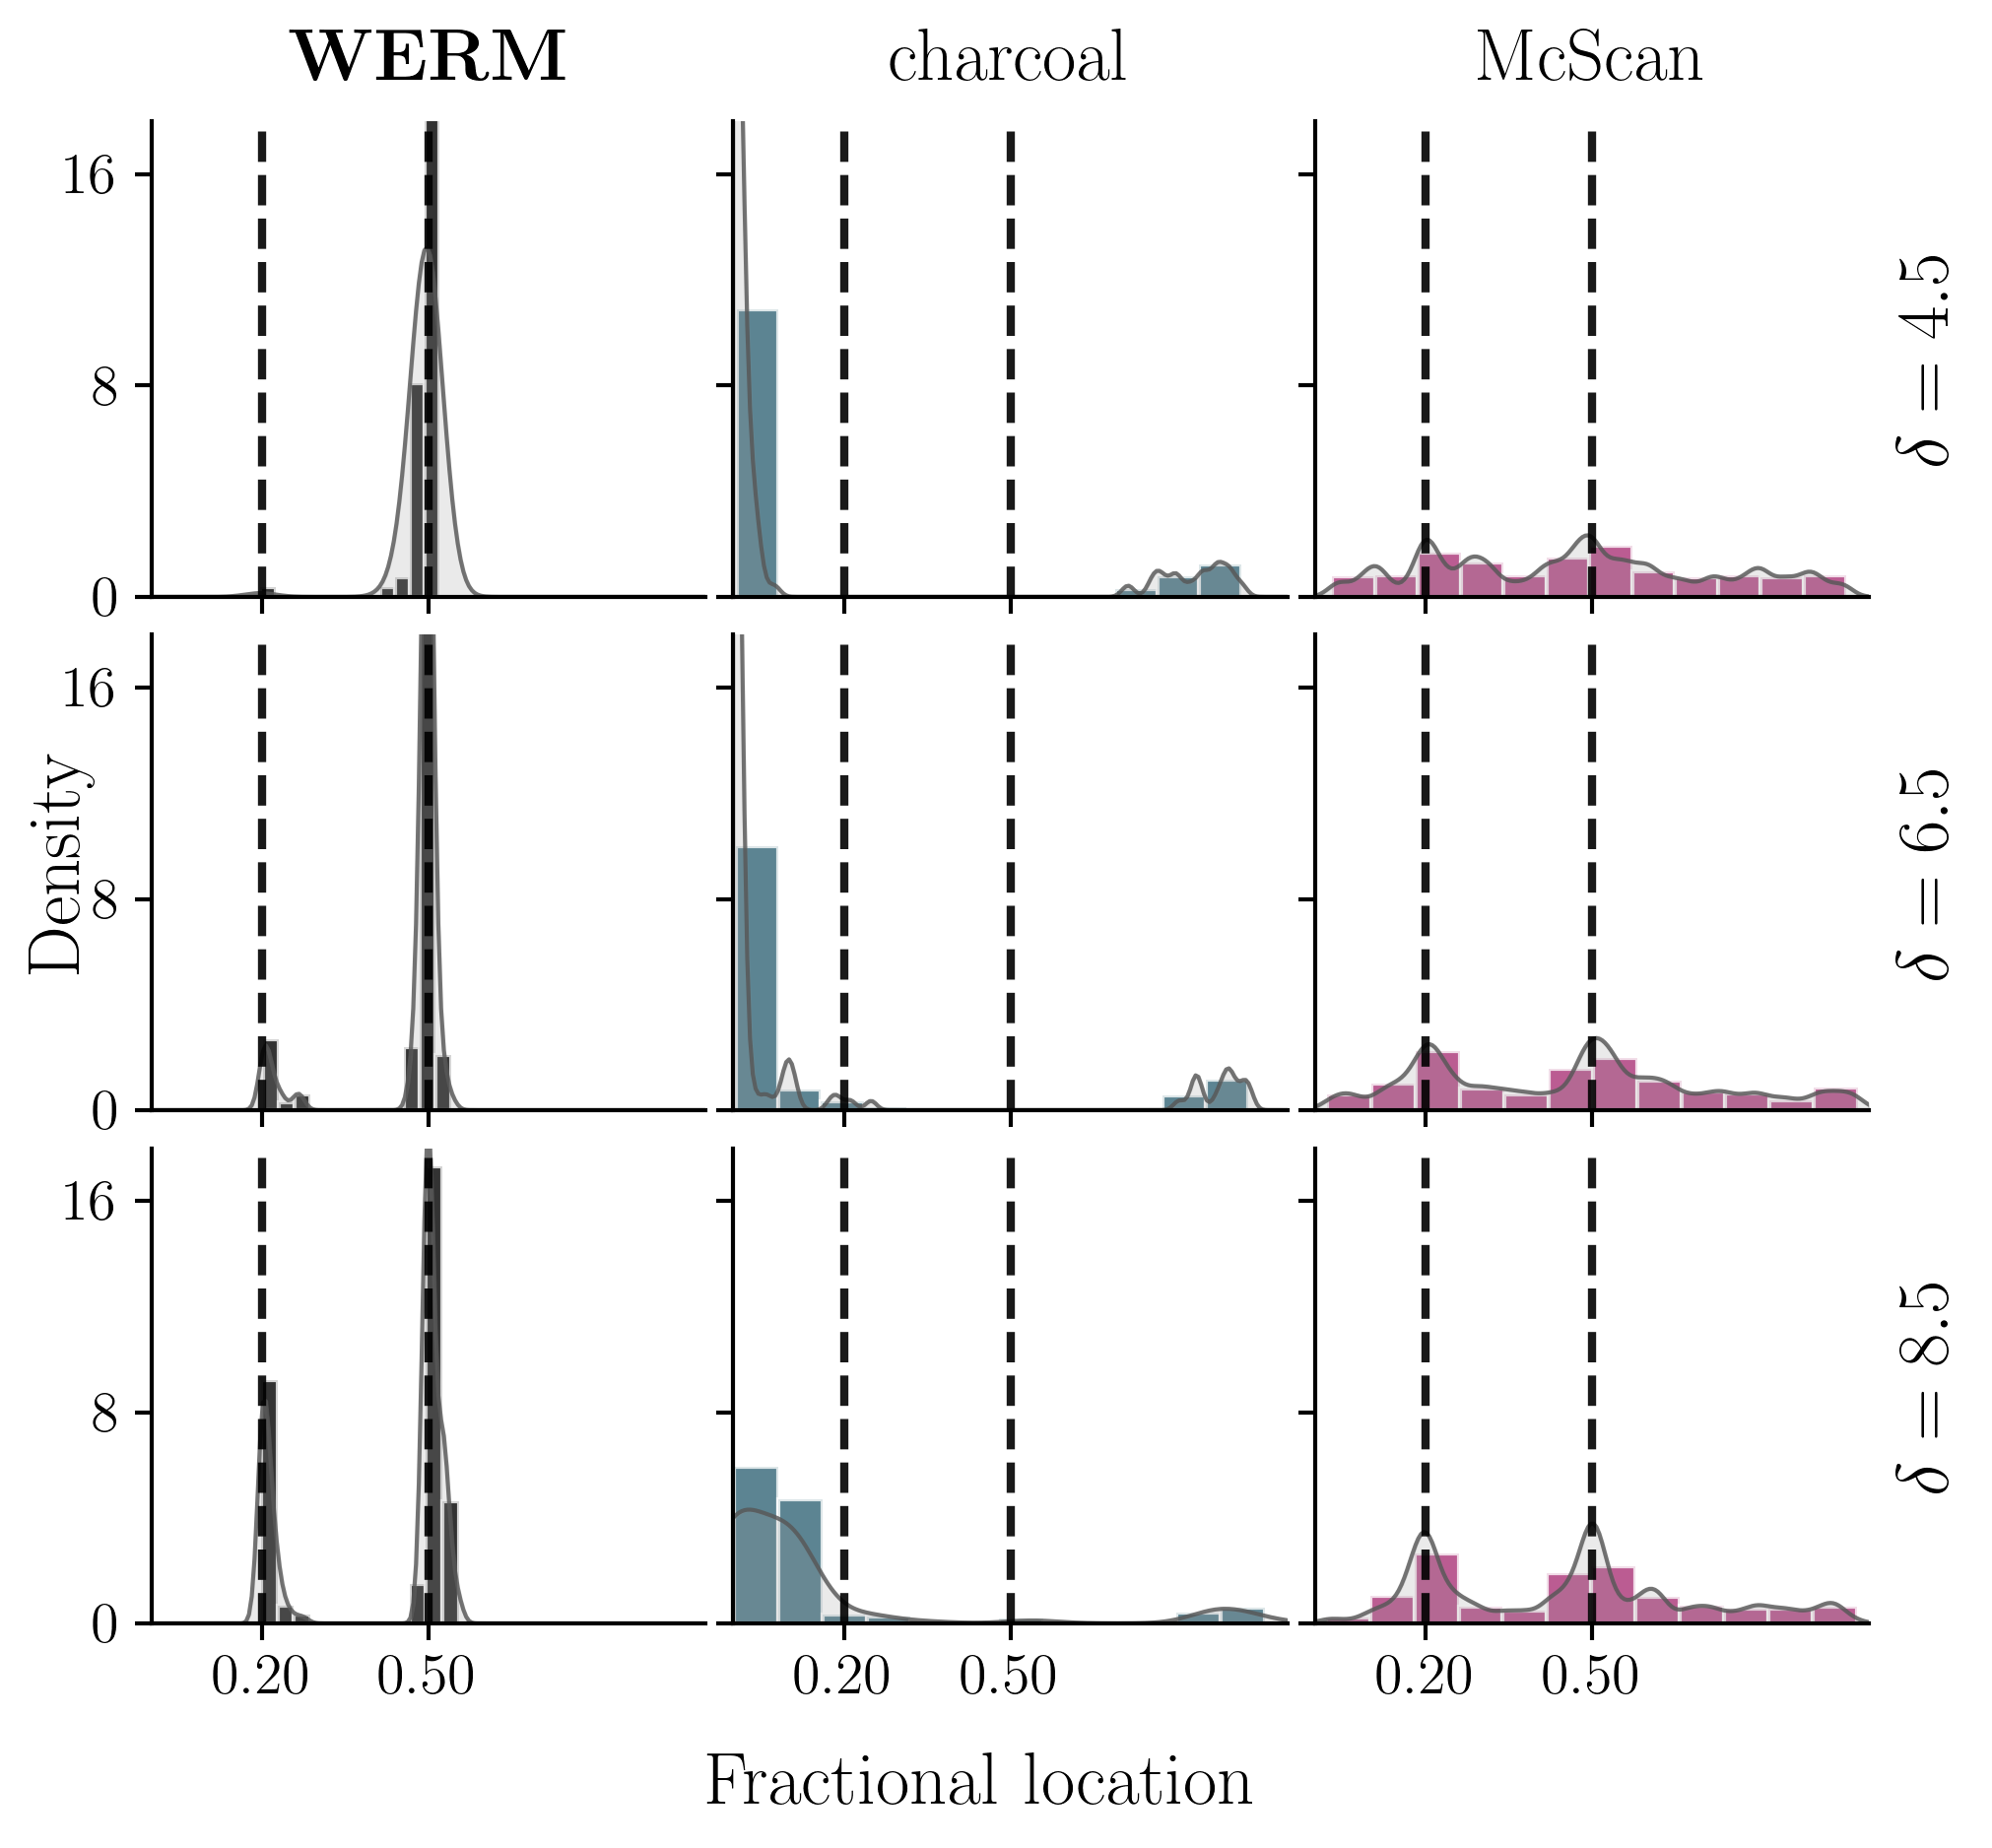

In [2]:
# This is the artifact loaded by the original canonical plotting cell, NOT the
# fresh WERM+P experiment. Each comparison keeps its own saved fits and timings.
original=load_saved('results/M2_upsample_final_alpha03_seed42_100trials.pkl')
results,params=original['results'],original['params']
deltas=np.asarray(params['delta_list']);truth=np.asarray(params['fractional_chgpt_locations'])
methods=['McScan','charcoal','WERM-unp-10fold']
curve_indices=np.arange(len(deltas))[1:-2:2]
charcoal_indices=np.arange(len(deltas))[1:-2]
charcoal_indices=charcoal_indices[deltas[charcoal_indices]<9.5]
histogram_indices=np.arange(len(deltas))[4:9:2]
assert params['num_trials']==100
np.testing.assert_allclose(deltas[histogram_indices],[4.5,6.5,8.5])
print('Original M2: McScan, charcoal, WERM (unpenalized, 10-fold CV); 100 trials per setting.')
for metric,ylabel in [('haus',r'Hausdorff dist. / $n$'),('size','No. change points'),('runtime','Runtime (s)')]:
    for kind in ('line','box'):
        with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
            if kind=='line':
                fig,ax=plt.subplots(figsize=(5.,4.));fig._canonical_m1=True
            else:fig,ax=paper_panel()
            rng=np.random.default_rng(42);handles=[]
            for j,method in enumerate(methods):
                label,color,marker,ls=METHODS[method]
                indices=charcoal_indices if method=='charcoal' else curve_indices
                values=np.asarray(results[f'{metric}_{method}'],float)[indices].copy()
                assert values.shape[1]==100
                if metric=='haus':
                    sizes=np.asarray(results[f'size_{method}'])[indices]
                    values=np.where(sizes>0,values,np.nan)
                if kind=='line':
                    error_series(ax,deltas[indices],values,label,color,marker,ls,scale=1)
                else:
                    for i,v in zip(indices,values):
                        box_group(ax,v,float(deltas[i])+(j-1)*.20,color,rng,width=.18,jitter=.06)
                    handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
            ax.set(xlabel=r'$\delta=n/p$',ylabel=ylabel)
            ax.set_xticks(deltas[curve_indices][::2])
            if metric=='size':
                ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                ax.set_ylim(0,params['L']+1);ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
            if metric=='runtime':
                ax.set_ylim(bottom=0)
                ax.legend(handles=handles if kind=='box' else None,loc='best',
                          prop={'size':14 if kind=='line' else 8},fancybox=True,frameon=True,framealpha=.4)
            if kind=='line':fig.tight_layout()
            export_plot(fig,f'M2_original_{metric}_{kind}')
with plt.rc_context(PAPER_STYLE):
    keys=list(reversed(methods));groups=[]
    for i in histogram_indices:
        n=int(deltas[i]*params['p']);row=[]
        for method in keys:
            parts=[np.asarray(cp).ravel() for index,cp in results[f'chgpts_{method}'] if index==i]
            cps=np.concatenate(parts) if parts else np.array([])
            row.append(cps[cps!=-1]/n)
        groups.append(row)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        'M2_original_hist',row_labels=[rf'$\delta={deltas[i]:g}$' for i in histogram_indices])

### Completed fresh four-method comparison, gamma = 6

Excluding charcoal R failures from plotted summaries: [(5, 54), (5, 82), (8, 41), (8, 81)]
Method | attempted trials | successful | empty | R/errors
McScan 1000 1000 0 0
charcoal 800 796 262 4
WERM 1000 1000 20 0
WERM+P 1000 1000 0 0
The saved artifact encoded four R errors as empty estimates. The new plots exclude them; valid empty estimates remain zero counts. Saved data are unchanged.


M2_fresh_haus_line


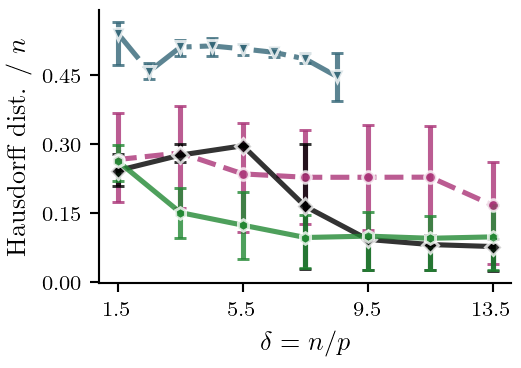

M2_fresh_haus_box


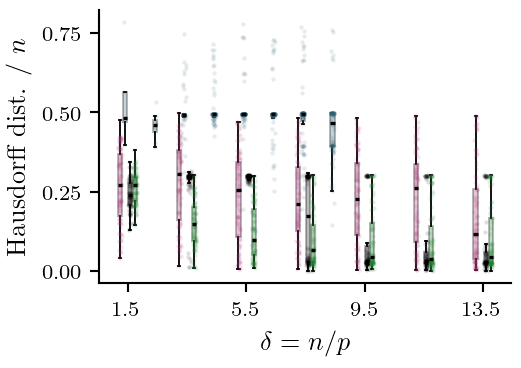

M2_fresh_size_line


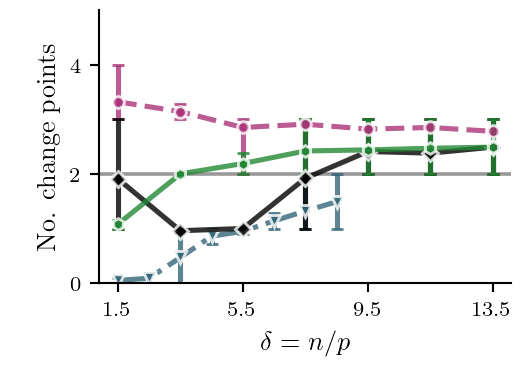

M2_fresh_size_box


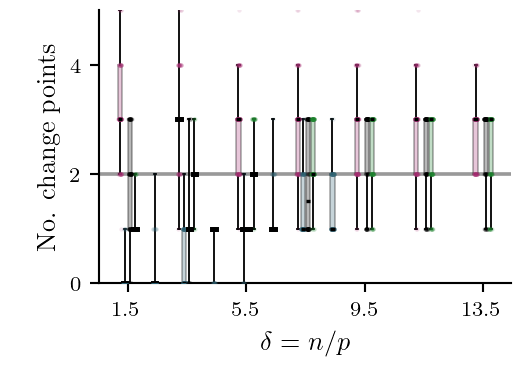

M2_fresh_runtime_line


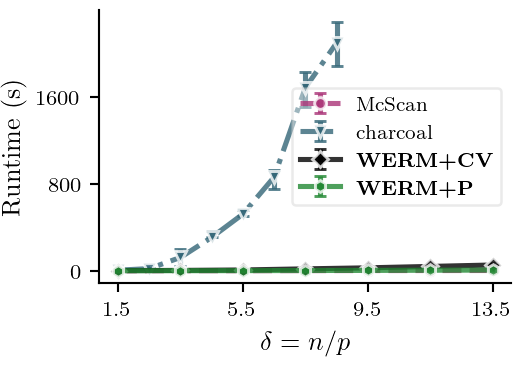

M2_fresh_runtime_box


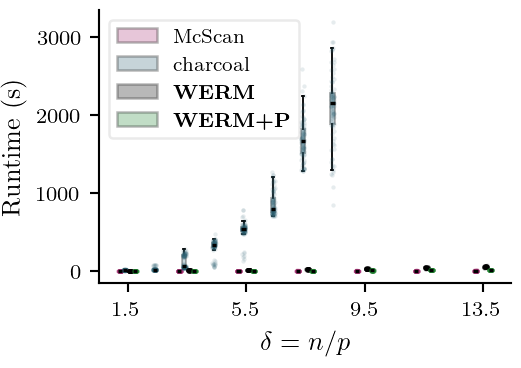

/tmp/ipykernel_3311065/2723109197.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


M2_fresh_hist: maximum density 31.56; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


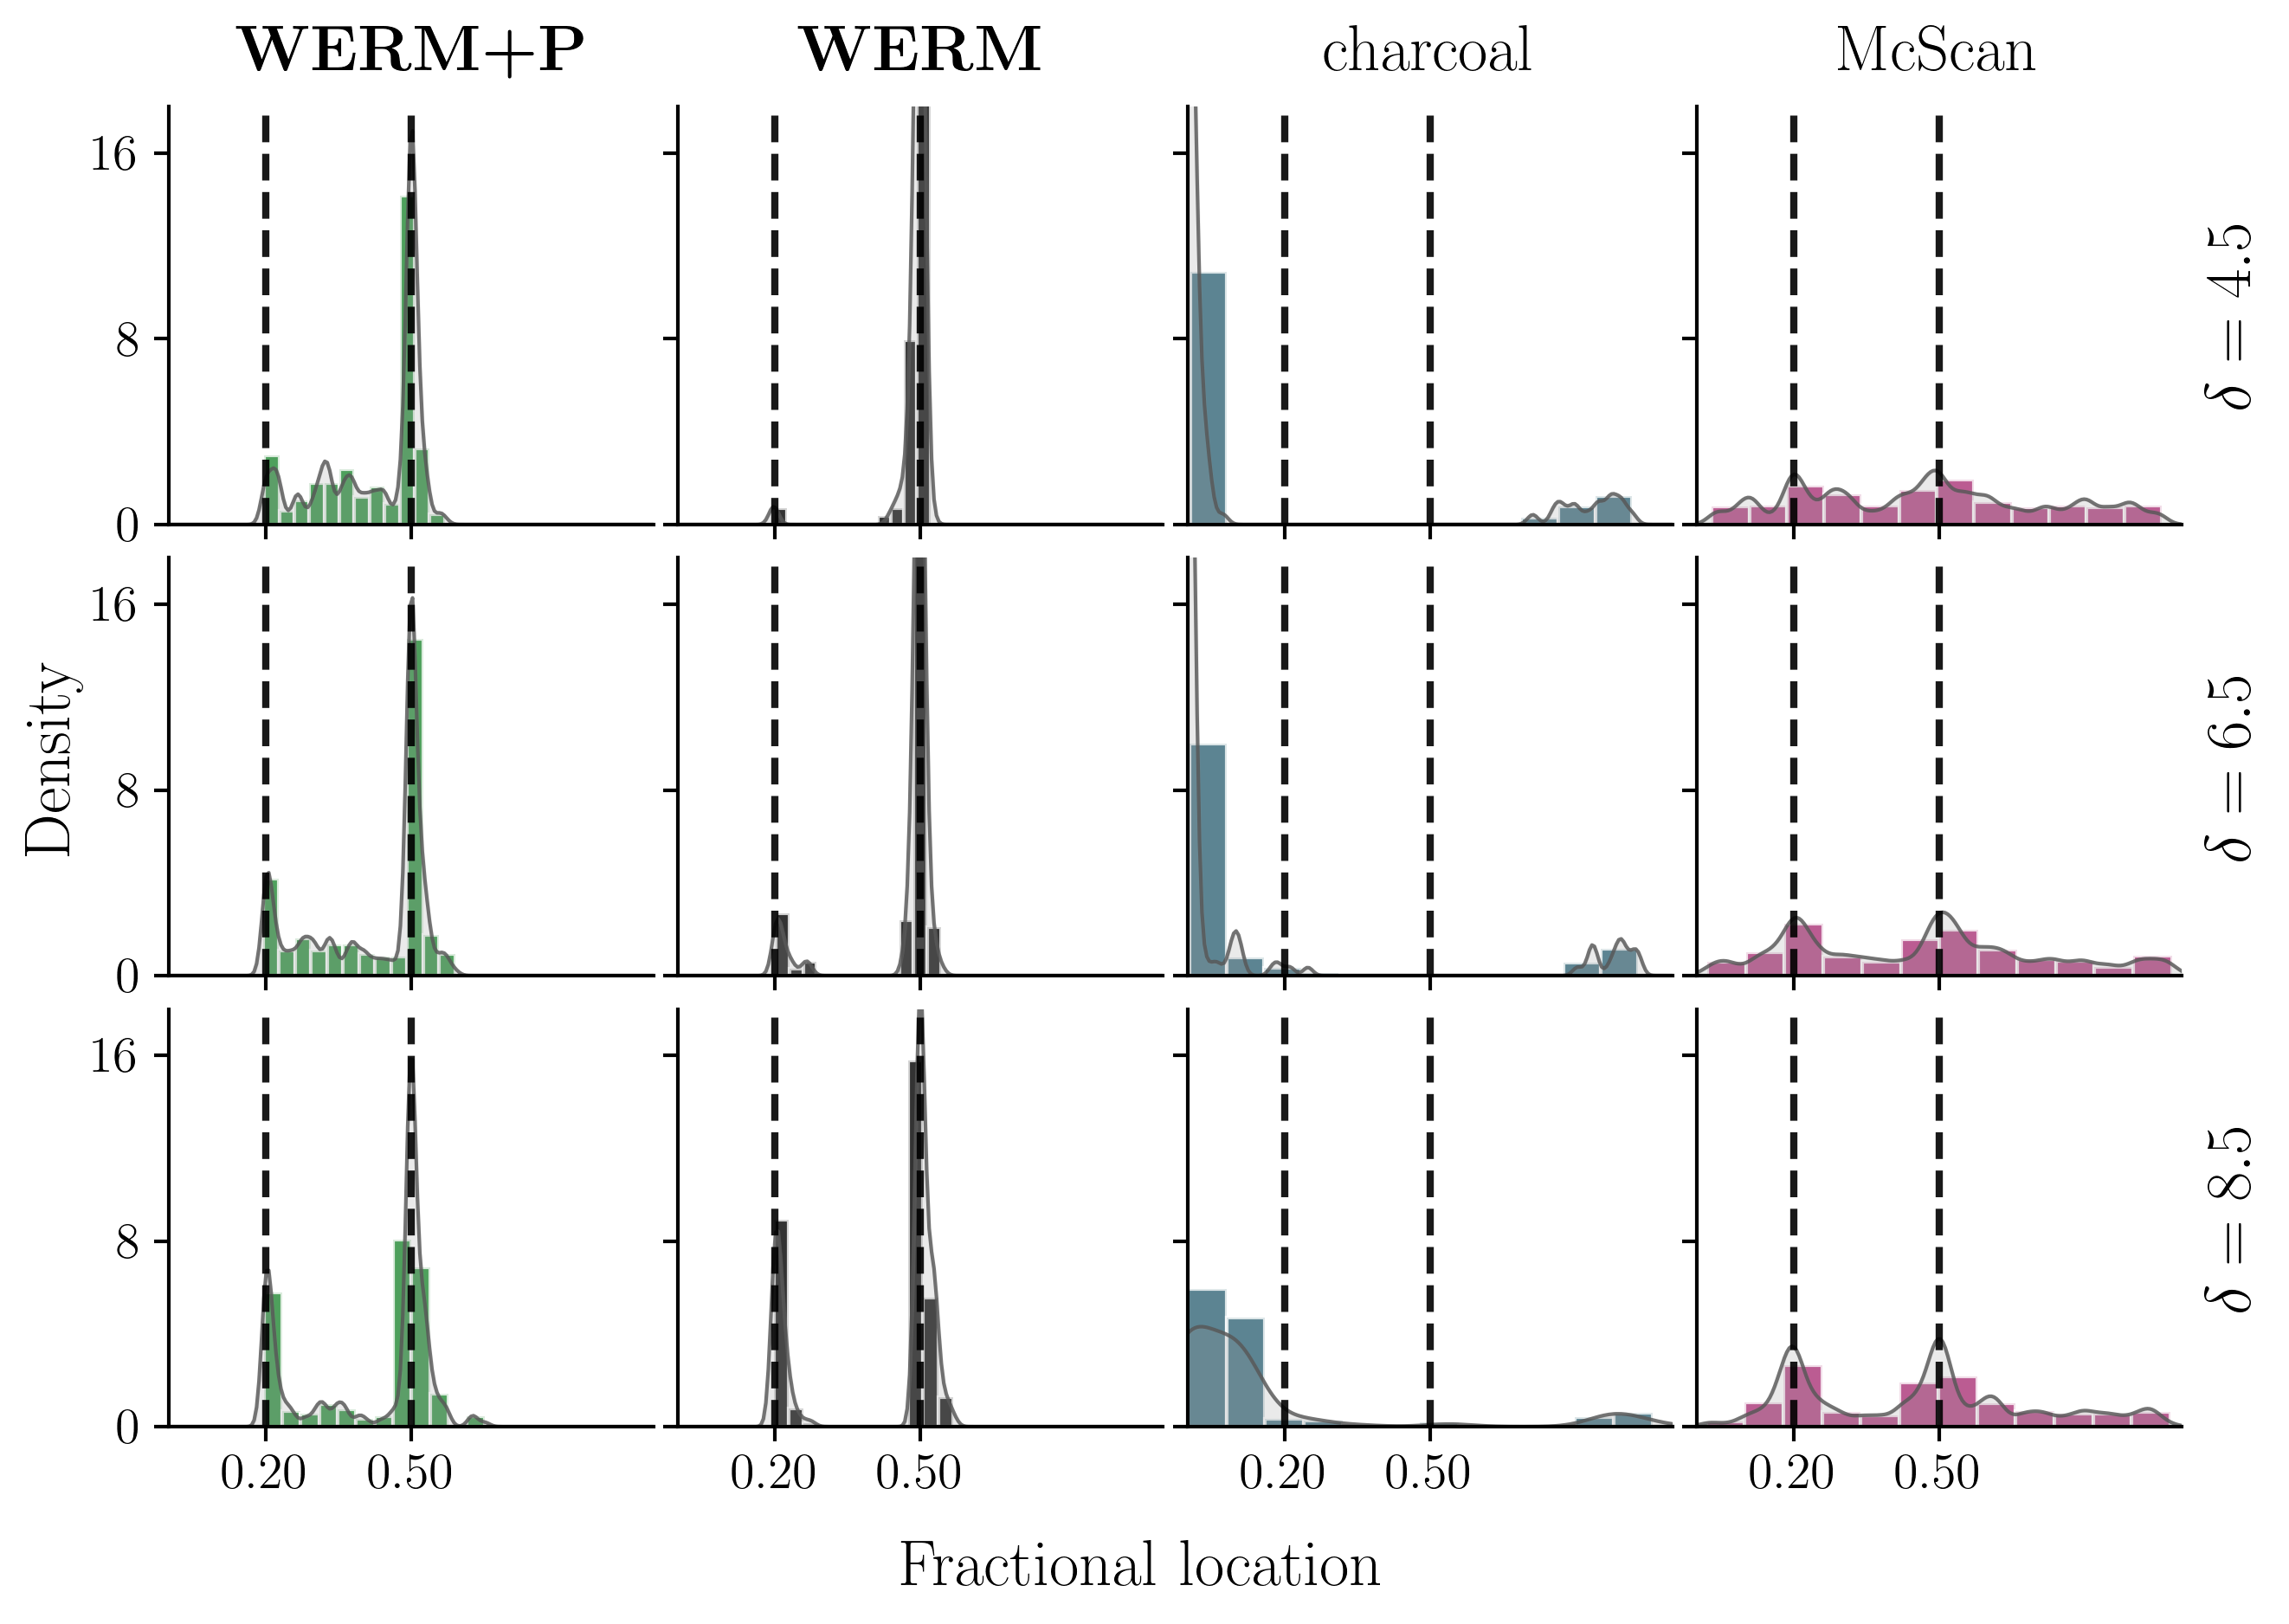

In [3]:
saved=load_saved('results/M2_upsample_final_WERM_plus_P_gamma6_fresh/comparison.pkl')
params=saved['params'];deltas=np.asarray(params['delta_list']);truth=np.asarray(params['fractional_chgpt_locations'])
methods=['McScan','charcoal','WERM','WERM+P']
METHODS['WERM']=(r'\textbf{WERM+CV}','black','D','-')
METHODS['WERM+P']=(r'\textbf{WERM+P}','#228833','h','-')
records=saved['trial_records']
failed={(r['setting'],r['trial']) for r in records if 'charcoal_R_error' in r.get('diagnostics',{})}
assert len(failed)==saved['charcoal_R_errors']==4
print('Excluding charcoal R failures from plotted summaries:',sorted(failed))
assert len({(r['setting'],r['trial']) for r in records})==len(records)
print('Method | attempted trials | successful | empty | R/errors')
for method in methods:
    indices=saved['charcoal_indices'] if method=='charcoal' else saved['setting_indices']
    entries=[r['estimates'][method] for r in records if r['setting'] in indices and method in r['estimates']]
    assert len(entries)==100*len(indices)
    for i in indices:
        assert {r['trial'] for r in records if r['setting']==i and method in r['estimates']}==set(range(100))
    errors=[e for e in entries if e['raw_cp'] is None]
    r_failures=len(failed) if method=='charcoal' else 0
    print(method,len(entries),len(entries)-len(errors)-r_failures,
          sum(e['size']==0 for e in entries)-r_failures,len(errors)+r_failures)
    for e in entries:
        if e['raw_cp'] is None:assert not np.isfinite(e['haus'])
        elif e['size']==0:assert not np.isfinite(e['haus'])
print('The saved artifact encoded four R errors as empty estimates. The new plots exclude them; valid empty estimates remain zero counts. Saved data are unchanged.')
with plt.rc_context(PAPER_STYLE):
    for metric,ylabel in [('haus',r'Hausdorff dist. / $n$'),('size','No. change points'),('runtime','Runtime (s)')]:
        for kind in ('line','box'):
            fig,ax=paper_panel();rng=np.random.default_rng(42);handles=[]
            for j,method in enumerate(methods):
                label,color,marker,ls=METHODS[method]
                indices=saved['charcoal_indices'] if method=='charcoal' else saved['curve_indices']
                source=np.asarray(saved['metrics'][method][metric]).copy()
                if method=='charcoal':
                    for setting,trial in failed:source[setting,trial]=np.nan
                values=source[indices]
                if kind=='line':error_series(ax,deltas[indices],values,label,color,marker,ls)
                else:
                    for i,v in zip(indices,values):box_group(ax,v,float(deltas[i])+(j-1.5)*.17,color,rng,width=.14,jitter=.055)
                    handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
            ax.set(xlabel=r'$\delta=n/p$',ylabel=ylabel)
            ax.set_xticks(deltas[saved['curve_indices']][::2])
            if metric=='size':
                ax.axhline(2,color='gray',lw=2.5*SCALE,alpha=.8,zorder=0)
                ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(0,5)
            if metric=='runtime':
                ax.legend(handles=handles if kind=='box' else None,loc='best',
                          prop={'size':8},fancybox=True,frameon=True,framealpha=.4)
            export_plot(fig,f'M2_fresh_{metric}_{kind}')
    for page,keys in enumerate([['WERM+P','WERM','charcoal','McScan']],1):
        groups=[]
        for i in saved['histogram_indices']:
            n=int(deltas[i]*params['p']);group=[]
            for method in keys:
                cps=[np.asarray(r['estimates'][method]['raw_cp'])/n for r in records
                     if r['setting']==i and method in r['estimates'] and r['estimates'][method]['raw_cp'] is not None]
                group.append(np.concatenate(cps))
            groups.append(group)
        histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
            'M2_fresh_hist',row_labels=[rf'$\delta={deltas[i]:g}$' for i in saved['histogram_indices']])

In [4]:
verify_sources()

Exported 14 figures to results/consistent_plots_20261102/M2; saved inputs unchanged.
